# CS781 – Merged Phase 1–4 (4 Phase-1 backbones)

| Backbone | Typical `.pt` | Arch |
|----------|---------------|------|
| `custom_mha` | `legal_lm_custom_mha.pt` | RoPE + MHA + SwiGLU |
| `mla_moe` | `legal_lm_mla_moe.pt` | MLA + MoE |
| `gqa_conv` | `legal_lm_gqa_conv.pt` | RoPE + GQA + Dual-path FFN |
| `gqa_alibi` | `legal_lm_alibi_gqa.pt` | **ALiBi + GQA** |

**Phase 1 = load only.** Set `BACKBONE` and paths; Phase 2/3/4 train heads on that backbone.

### Why different tokenizers?

Each Phase-1 model was trained with its own byte-level BPE (different merge tables → different vocab sizes).  
Using a single shared tokenizer would either:
- produce out-of-range token ids (CUDA assert / silent corruption), or
- feed the model a completely different tokenisation than the one it saw during pre-training.

So we keep **one tokenizer file per backbone** (`.pkl` or `.json`) and load the matching one whenever we switch `BACKBONE`. The model’s embedding matrix size is still taken from the checkpoint; we only assert that it matches the tokenizer’s `vocab_size`.


In [ ]:
!pip -q install ijson tqdm

In [ ]:
!mkdir -p /kaggle/working/phase6
!cp -r /kaggle/input/datasets/vidya6364/phase6-models/phase6/* /kaggle/working/phase6/

!mkdir -p /kaggle/working/phase1_models
!cp -r /kaggle/input/datasets/vidya6364/phase1-models-1k/* /kaggle/working/phase1_models/
!cp -r /kaggle/input/datasets/vidya6364/phase1-models/* /kaggle/working/phase1_models/
!ls

cs781_phase1  phase1_models  phase6  state.db


In [ ]:
import os, sys, re, gc, json, math, time, random, hashlib, unicodedata, zipfile
from collections import Counter, defaultdict
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

print("device:", DEVICE, "| amp:", AMP_DTYPE if USE_AMP else None)

device: cpu | amp: None


## 0. Paths & global config

Edit `DATASET_DIR`, `BACKBONE`, and the four entries in `TOK_PATHS`.  
Everything else is derived from those.


In [ ]:
!ls phase1_models

gqa_conv_1ksteps.pt		 legal_bpe_tokenizer_gqa_alibi.pkl
latest_checkpoint_alibi_gqa.pt	 legal_bpe_v2.json
latest_checkpoint_gqa_conv.pt	 legal_lm_alibi_gqa.pt
latest_checkpoint_mla_moe_1k.pt  legal_lm_custom_mha.pt
latest_checkpoint_mla_moe.pt	 legal_lm_gqa_conv.pt
legal_bpe_custom_mha.json	 legal_lm_mla_moe_1k.pt
legal_bpe_gqa_conv.json		 legal_lm_mla_moe.pt
legal_bpe_mla_moe.json


In [ ]:
# ── CHANGE THESE ────────────────────────────────────────────────────────────
DATASET_DIR = "/kaggle/working/phase1_models"   # folder with .pt + tokenizers
BACKBONE    = "mla_moe"   # "custom_mha" | "mla_moe" | "gqa_conv" | "gqa_alibi"

RUN_PHASE2_TRAIN = True
RUN_PHASE3_TRAIN = True

try:
    from kaggle_secrets import UserSecretsClient
    from huggingface_hub import login
    HF_TOKEN = UserSecretsClient().get_secret("HF")
    print(HF_TOKEN)
    login(token=HF_TOKEN)
    print("HF login OK")
except Exception as e:
    HF_TOKEN = os.environ.get("HF_TOKEN")
    print("HF login skipped:", e)

HF_REPO = "Exploration-Lab/CS-781-Capstone"
OUT_DIR = "/kaggle/working/cs781_phase1" if os.path.isdir("/kaggle/working") else "./cs781_phase1"
P2_OUT  = "/kaggle/working/phase2_lner" if os.path.isdir("/kaggle/working") else "./phase2_lner"
P3_OUT  = "/kaggle/working/phase3" if os.path.isdir("/kaggle/working") else "./phase3"
P4_BASE = "/kaggle/working/phase4" if os.path.isdir("/kaggle/working") else "./phase4"
os.makedirs(P2_OUT, exist_ok=True)
os.makedirs(P3_OUT, exist_ok=True)
os.makedirs(P4_BASE, exist_ok=True)

def _first(*cands):
    """Return the first path that actually exists on disk."""
    for p in cands:
        if p and os.path.exists(p):
            return p
    return cands[0]

# ── Per-backbone tokenizer paths ───────────────────────────────────────────
# Drop your four .pkl (or .json) files into DATASET_DIR and adjust the names
# below if they differ.  The loader accepts both formats.
TOK_PATHS = {
    "custom_mha": _first(
        os.path.join(DATASET_DIR, "legal_bpe_custom_mha.json"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),          # legacy fallback
    ),
    "mla_moe": _first(
        os.path.join(DATASET_DIR, "legal_bpe_mla_moe.json"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
    "gqa_conv": _first(
        os.path.join(DATASET_DIR, "legal_bpe_gqa_conv.json"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
    "gqa_alibi": _first(
        os.path.join(DATASET_DIR, "legal_bpe_tokenizer_gqa_alibi.pkl"),
        os.path.join(DATASET_DIR, "legal_bpe_alibi_gqa.pkl"),
        os.path.join(DATASET_DIR, "legal_bpe_v2.json"),
    ),
}

TOKENIZER_PATH = TOK_PATHS[BACKBONE]

# ── Checkpoints ────────────────────────────────────────────────────────────
CKPT_V2 = _first(
    os.path.join(DATASET_DIR, "legal_lm_custom_mha.pt"),
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_custom_mha.pt"),
)
CKPT_V3 = _first(
    os.path.join(DATASET_DIR, "legal_lm_mla_moe_1k.pt"),
    os.path.join(DATASET_DIR, "legal_lm_mla_moe.pt"),
    os.path.join(DATASET_DIR, "latest_checkpoint_mla_moe.pt"),
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_mla_moe.pt"),
)
CKPT_GQA = _first(
    os.path.join(DATASET_DIR, "legal_lm_gqa_conv.pt"),
    os.path.join(DATASET_DIR, "latest_checkpoint_gqa_conv.pt"),
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_gqa_conv.pt"),
)
CKPT_ALIBI = _first(
    os.path.join(DATASET_DIR, "legal_lm_alibi_gqa.pt"),
    os.path.join(DATASET_DIR, "latest_checkpoint_alibi_gqa.pt"),
    os.path.join(DATASET_DIR, "legal_lm_alibi.pt"),
    os.path.join(DATASET_DIR, "phase1_models", "legal_lm_alibi_gqa.pt"),
)

CKPTS = {"custom_mha": CKPT_V2, "mla_moe": CKPT_V3, "gqa_conv": CKPT_GQA, "gqa_alibi": CKPT_ALIBI}
PHASE1_CKPT = CKPTS[BACKBONE]

print("BACKBONE     :", BACKBONE)
print("Tokenizer    :", TOKENIZER_PATH, os.path.exists(TOKENIZER_PATH))
for k, v in CKPTS.items():
    print(f"  {k:12s}:", v, os.path.exists(v))
print("Phase-1 used :", PHASE1_CKPT, os.path.exists(PHASE1_CKPT))
for k, p in TOK_PATHS.items():
    print(f"  tok[{k:12s}]:", p, os.path.exists(p))


## 1. Shared text cleaning + byte-level BPE tokenizer

The same cleaning pipeline is used for every backbone.  
Only the **merge table / vocab** changes with `BACKBONE`.


In [ ]:
_QUOTES = str.maketrans({"“": '"', "”": '"', "„": '"', "‘": "'", "’": "'", "‚": "'", "`": "'", "´": "'",
                         "–": "-", "—": "-", "−": "-", "\u00ad": ""})
_CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]")
_WS = re.compile(r"[ \t\u00a0\u1680\u2000-\u200b\u202f\u205f\u3000\ufeff]+")
_DOTS = re.compile(r"\.{4,}|(?:\. ){4,}")
_RULE = re.compile(r"[_\-=*~#]{3,}")
_PAGE = re.compile(r"(?mi)^[ \t]*(?:page\s+)?\d{1,4}[ \t]*$\n?")
_HYPH = re.compile(r"(?<=[a-z])-\n(?=[a-z])")
_WRAP = re.compile(r"(?<=[a-z,;])\n(?=[a-z(])")

def clean_text(t):
    """Light, conservative normalisation of legal text."""
    t = unicodedata.normalize("NFKC", str(t)).replace("\r\n", "\n").replace("\r", "\n")
    t = t.translate(_QUOTES)
    t = _CTRL.sub(" ", t)
    t = _HYPH.sub("", t)
    t = _DOTS.sub("...", t)
    t = _RULE.sub(" ", t)
    t = _PAGE.sub("", t)
    t = _WS.sub(" ", t)
    t = re.sub(r" *\n *", "\n", t)
    t = _WRAP.sub(" ", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()


class BPETokenizer:
    SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]
    _split = re.compile(r" ?[^\W\d_]+| ?\d+| ?[^\s\w]+| ?_+|\s+(?!\S)|\s+")

    def __init__(self, vocab_size=12000):
        self.vocab_size = vocab_size
        self.merges = []
        self._reset()

    def _reset(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        self._cache = {}

    def _build(self):
        self.itos = list(self.SPECIALS) + [bytes([i]) for i in range(256)]
        seen = set(self.itos[4:])
        for a, b in self.merges:
            m = a + b
            if m not in seen:
                seen.add(m); self.itos.append(m)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.ranks = {pair: r for r, pair in enumerate(self.merges)}
        self.merged = {pair: pair[0] + pair[1] for pair in self.merges}
        self._cache = {}
        self.pad_id, self.unk_id, self.bos_id, self.eos_id = 0, 1, 2, 3
        self.vocab_size = len(self.itos)

    def _word(self, w):
        r = self._cache.get(w)
        if r is not None: return r
        toks = [bytes([b]) for b in w.encode("utf-8")]
        while len(toks) > 1:
            best_i, best_r = -1, 1 << 60
            for i in range(len(toks) - 1):
                r_ = self.ranks.get((toks[i], toks[i + 1]), 1 << 60)
                if r_ < best_r: best_i, best_r = i, r_
            if best_i < 0: break
            toks[best_i:best_i + 2] = [toks[best_i] + toks[best_i + 1]]
        r = [self.stoi.get(t, self.unk_id) for t in toks]
        if len(self._cache) > 500_000: self._cache.clear()
        self._cache[w] = r
        return r

    def encode(self, text, add_bos=False, add_eos=False):
        ids = []
        if add_bos: ids.append(self.bos_id)
        for w in self._split.findall(text):
            ids.extend(self._word(w))
        if add_eos: ids.append(self.eos_id)
        return ids

    def decode(self, ids):
        if isinstance(ids, torch.Tensor): ids = ids.tolist()
        parts = []
        for i in ids:
            if i < 4: continue
            t = self.itos[i] if i < len(self.itos) else b""
            if isinstance(t, bytes):
                try: parts.append(t.decode("utf-8"))
                except Exception: parts.append("�")
            else:
                parts.append(str(t))
        return "".join(parts)

    def save(self, path):
        with open(path, "w") as f:
            json.dump({"merges": [[a.hex(), b.hex()] for a, b in self.merges]}, f)

    @classmethod
    def load(cls, path):
        with open(path) as f:
            data = json.load(f)
        tok = cls()
        tok.merges = [(bytes.fromhex(a), bytes.fromhex(b)) for a, b in data["merges"]]
        tok._build()
        return tok

    @classmethod
    def load_any(cls, path):
        """Load from either the original JSON format or a pickle dump.

        Why this exists
        ---------------
        Phase-1 models were trained with different BPE tables.  Some exports
        are the original JSON (list of hex merges); others are full pickle
        dumps of the tokenizer object or of a dict containing "merges".
        This helper accepts both so you can drop .pkl files straight into
        DATASET_DIR without converting them first.
        """
        path = str(path)
        if path.endswith((".pkl", ".pickle")):
            import pickle
            with open(path, "rb") as f:
                obj = pickle.load(f)
            if isinstance(obj, cls):
                return obj
            if isinstance(obj, dict):
                tok = cls()
                if "merges" in obj:
                    merges = obj["merges"]
                    # hex-encoded (from .json export) or raw bytes
                    if merges and isinstance(merges[0][0], str):
                        tok.merges = [(bytes.fromhex(a), bytes.fromhex(b)) for a, b in merges]
                    else:
                        tok.merges = [(bytes(a), bytes(b)) for a, b in merges]
                    tok._build()
                    return tok
                # full state-dict style
                for k, v in obj.items():
                    setattr(tok, k, v)
                if not getattr(tok, "stoi", None):
                    tok._build()
                return tok
            raise TypeError(f"Unrecognised pickle content in {path}: {type(obj)}")
        # original JSON path
        return cls.load(path)


assert os.path.exists(TOKENIZER_PATH), f"Tokenizer not found at {TOKENIZER_PATH}"
tokenizer = BPETokenizer.load_any(TOKENIZER_PATH)
print(f"Tokenizer loaded | vocab_size = {tokenizer.vocab_size} | from {TOKENIZER_PATH}")

# Pre-load every available tokenizer so Phase 4 can switch per experiment.
# Specials (pad/unk/bos/eos = 0/1/2/3) are identical across files; only merges/vocab differ.
TOKENIZERS = {}
for _name, _path in TOK_PATHS.items():
    if os.path.exists(_path):
        TOKENIZERS[_name] = BPETokenizer.load_any(_path)
        print(f"  tok[{_name}]: vocab={TOKENIZERS[_name].vocab_size}  <- {_path}")
    else:
        print(f"  tok[{_name}]: MISSING {_path}")
# keep global `tokenizer` pointing at the BACKBONE selected in the config cell
tokenizer = TOKENIZERS.get(BACKBONE, tokenizer)
print(f"Active tokenizer for BACKBONE={BACKBONE}: vocab={tokenizer.vocab_size}")


Tokenizer loaded | vocab_size = 30000 | from /kaggle/working/phase1_models/legal_bpe_mla_moe.json
  tok[custom_mha]: vocab=24000  <- /kaggle/working/phase1_models/legal_bpe_custom_mha.json
  tok[mla_moe]: vocab=30000  <- /kaggle/working/phase1_models/legal_bpe_mla_moe.json
  tok[gqa_conv]: vocab=30000  <- /kaggle/working/phase1_models/legal_bpe_gqa_conv.json
  tok[gqa_alibi]: vocab=32000  <- /kaggle/working/phase1_models/legal_bpe_tokenizer_gqa_alibi.pkl
Active tokenizer for BACKBONE=mla_moe: vocab=30000


In [ ]:
for name, tok in TOKENIZERS.items():
    if not hasattr(tok, 'unk_id'):
        tok.unk_id = 1
    if not hasattr(tok, 'pad_id'):
        tok.pad_id = 0
    if not hasattr(tok, 'bos_id'):
        tok.bos_id = 2
    if not hasattr(tok, 'eos_id'):
        tok.eos_id = 3

## 2. Shared building blocks (RMSNorm, RoPE)

In [ ]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.w = nn.Parameter(torch.ones(d))
        self.weight = self.w  # alias for alibi ckpts
        self.eps = eps
    def forward(self, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)).type_as(x) * self.w


class RoPE(nn.Module):
    def __init__(self, hd, max_len, base=10000.0):
        super().__init__()
        inv = 1.0 / (base ** (torch.arange(0, hd, 2).float() / hd))
        fr = torch.outer(torch.arange(max_len).float(), inv)
        self.register_buffer("cos", fr.cos(), persistent=False)
        self.register_buffer("sin", fr.sin(), persistent=False)
    def forward(self, x, start=0):                      # x: (b, heads, t, hd)
        t = x.size(2)
        cos = self.cos[start:start + t].to(x.dtype)
        sin = self.sin[start:start + t].to(x.dtype)
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat((x1 * cos - x2 * sin, x2 * cos + x1 * sin), dim=-1)


## 3. Architecture A – LegalLM v2 (standard decoder)

In [ ]:
class AttentionV2(nn.Module):
    def __init__(self, dim, heads, block_size):
        super().__init__()
        assert dim % heads == 0
        self.h, self.hd = heads, dim // heads
        self.qkv = nn.Linear(dim, 3 * dim, bias=False)
        self.proj = nn.Linear(dim, dim, bias=False)
        self.rope = RoPE(self.hd, block_size)
    def forward(self, x, mask=None, cache=None, start=0):
        b, t, c = x.shape
        q, k, v = self.qkv(x).reshape(b, t, 3, self.h, self.hd).permute(2, 0, 3, 1, 4)
        q, k = self.rope(q, start), self.rope(k, start)
        if cache is not None:
            if cache[0] is not None:
                k = torch.cat([cache[0], k], 2)
                v = torch.cat([cache[1], v], 2)
            cache = (k, v)
        if mask is not None:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
        elif t > 1:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            y = F.scaled_dot_product_attention(q, k, v)
        return self.proj(y.transpose(1, 2).reshape(b, t, c)), cache


class SwiGLU(nn.Module):
    def __init__(self, dim, mult=8/3):
        super().__init__()
        hid = int(mult * dim / 64) * 64
        self.w13 = nn.Linear(dim, 2 * hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
    def forward(self, x):
        a, b = self.w13(x).chunk(2, dim=-1)
        return self.w2(F.silu(a) * b)


class BlockV2(nn.Module):
    def __init__(self, dim, heads, block_size):
        super().__init__()
        self.n1, self.n2 = RMSNorm(dim), RMSNorm(dim)
        self.attn = AttentionV2(dim, heads, block_size)
        self.mlp = SwiGLU(dim)
    def forward(self, x, mask=None, cache=None, start=0):
        h, cache = self.attn(self.n1(x), mask, cache, start)
        x = x + h
        return x + self.mlp(self.n2(x)), cache


class LegalLMv2(nn.Module):
    """Standard RoPE + RMSNorm + SwiGLU decoder (Phase-1 v2)."""
    def __init__(self, vocab_size, dim=768, layers=8, heads=12, block_size=1024):
        super().__init__()
        self.block_size = block_size
        self.wte = nn.Embedding(vocab_size, dim)
        self.blocks = nn.ModuleList([BlockV2(dim, heads, block_size) for _ in range(layers)])
        self.ln_f = RMSNorm(dim)
        self.lm_head = nn.Linear(dim, vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight  # weight tying

    def forward(self, idx, targets=None):
        x = self.wte(idx)
        for blk in self.blocks:
            x, _ = blk(x)
        logits = self.lm_head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    def step(self, idx, caches, start, mask=None):
        x = self.wte(idx)
        new = []
        for blk, c in zip(self.blocks, caches):
            x, c = blk(x, mask, c, start)
            new.append(c)
        return self.lm_head(self.ln_f(x[:, -1:]))[:, 0], new


def load_v2(path=None, device=DEVICE):
    path = path or CKPT_V2
    assert os.path.exists(path), f"v2 checkpoint missing: {path}"
    ck = torch.load(path, map_location="cpu", weights_only=False)
    # tolerate both raw state-dict and full training checkpoint
    if isinstance(ck, dict) and "model" in ck:
        state = ck["model"]
        cfg = ck.get("config", {})
    elif isinstance(ck, dict) and "model_state" in ck:
        state = ck["model_state"]
        cfg = ck.get("config", {})
    else:
        state = ck
        cfg = {}
    # strip possible torch.compile prefix
    state = {k.replace("_orig_mod.", ""): v for k, v in state.items()}
    vocab = cfg.get("vocab_size", state.get("wte.weight", torch.empty(0)).shape[0] or tokenizer.vocab_size)
    dim   = cfg.get("dim", cfg.get("n_embd", 768))
    layers= cfg.get("layers", cfg.get("n_layer", 8))
    heads = cfg.get("heads", cfg.get("n_head", 12))
    bs    = cfg.get("block_size", 1024)
    model = LegalLMv2(vocab, dim, layers, heads, bs)
    model.load_state_dict(state, strict=False)
    model.to(device).eval()
    print(f"v2 loaded | params={sum(p.numel() for p in model.parameters())/1e6:.1f}M | from {path}")
    return model

## 4. Architecture B – LegalLM v3 (MLA + domain-guided MoE)

In [ ]:
# Default hyper-params used when the checkpoint does not embed a config
V3_DEFAULTS = dict(
    dim=640, layers=8, heads=10, block_size=1024,
    d_c=128, d_cq=256, d_nope=64, d_rope=32, d_v=64,
    n_routed=8, topk=2,
    expert_hid=512, shared_hid=1024, dense_hid=1728,
    dense_first=1, n_domains=4,
)


class MLA(nn.Module):
    """Multi-head Latent Attention (DeepSeek-style) with decoupled RoPE."""
    def __init__(self, c):
        super().__init__()
        dim, H = c["dim"], c["heads"]
        self.h = H
        self.dc, self.dn, self.dr, self.dv = c["d_c"], c["d_nope"], c["d_rope"], c["d_v"]
        self.dq = nn.Linear(dim, c["d_cq"], bias=False)
        self.q_norm = RMSNorm(c["d_cq"])
        self.uq = nn.Linear(c["d_cq"], H * (self.dn + self.dr), bias=False)
        self.dkv = nn.Linear(dim, self.dc + self.dr, bias=False)
        self.kv_norm = RMSNorm(self.dc)
        self.uk = nn.Linear(self.dc, H * self.dn, bias=False)
        self.uv = nn.Linear(self.dc, H * self.dv, bias=False)
        self.o = nn.Linear(H * self.dv, dim, bias=False)
        self.rope = RoPE(self.dr, c["block_size"])
        self.scale = 1.0 / math.sqrt(self.dn + self.dr)

    def forward(self, x, mask=None, cache=None, start=0):
        b, t, _ = x.shape
        q = self.uq(self.q_norm(self.dq(x))).reshape(b, t, self.h, self.dn + self.dr).transpose(1, 2)
        q_nope, q_rope = q.split([self.dn, self.dr], dim=-1)
        ckv, k_rope = self.dkv(x).split([self.dc, self.dr], dim=-1)
        ckv = self.kv_norm(ckv)
        q_rope = self.rope(q_rope, start)
        k_rope = self.rope(k_rope.unsqueeze(1), start)  # (b,1,t,dr)
        if cache is not None:
            if cache[0] is not None:
                ckv = torch.cat([cache[0], ckv], 1)
                k_rope = torch.cat([cache[1], k_rope], 2)
            cache = (ckv, k_rope)
        k_nope = self.uk(ckv).reshape(b, -1, self.h, self.dn).transpose(1, 2)
        v = self.uv(ckv).reshape(b, -1, self.h, self.dv).transpose(1, 2)
        k = torch.cat([k_nope, k_rope.expand(-1, self.h, -1, -1)], dim=-1)
        q = torch.cat([q_nope, q_rope], dim=-1)
        if mask is not None:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, scale=self.scale)
        elif t > 1:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True, scale=self.scale)
        else:
            y = F.scaled_dot_product_attention(q, k, v, scale=self.scale)
        return self.o(y.transpose(1, 2).reshape(b, t, -1)), cache


class Expert(nn.Module):
    def __init__(self, dim, hid):
        super().__init__()
        self.w1 = nn.Linear(dim, hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
        self.w3 = nn.Linear(dim, hid, bias=False)
    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))

class DeepSeekMoE(nn.Module):
    def __init__(self, c):
        super().__init__()
        dim, self.n, self.k, self.D = c["dim"], c["n_routed"], c["topk_experts"], c["n_domains"]
        assert self.n % self.D == 0, "n_routed must be a multiple of n_domains"
        self.router = nn.Linear(dim, self.n, bias=False)
        self.experts = nn.ModuleList([DenseFFN(dim, c["expert_hid"]) for _ in range(self.n)])
        self.shared = DenseFFN(dim, c["shared_hid"])

    def forward(self, x, domain=None):
        b, t, d = x.shape
        xf = x.reshape(-1, d); N = xf.size(0)
        probs = self.router(xf).float().softmax(-1)                                   # (N, n_routed)
        topv, topi = probs.topk(self.k, dim=-1)
        topv = topv / topv.sum(-1, keepdim=True)
        flat_e = topi.reshape(-1)
        order = flat_e.argsort()
        tok = order // self.k                                                         # token index for each (sorted) assignment
        w = topv.reshape(-1)[order]
        counts = torch.bincount(flat_e, minlength=self.n)
        xs, outs, pos = xf[tok], [], 0
        for e, cnt in enumerate(counts.tolist()):
            if cnt:
                outs.append(self.experts[e](xs[pos:pos + cnt])); pos += cnt
        ys = torch.cat(outs, 0)
        routed = torch.zeros(N, d, dtype=ys.dtype, device=x.device).index_add_(0, tok, ys * w[:, None].to(ys.dtype))
        y = (self.shared(xf) + routed).reshape(b, t, d)

        z = probs.new_zeros(())
        bal, dom, acc = z, z, z
        if self.training:                                                             # switch-style load balancing
            f = counts.float() / (N * self.k)
            bal = self.n * (f * probs.mean(0)).sum()
        if domain is not None:                                                        # domain-guided routing
            g = probs.reshape(N, self.D, self.n // self.D).sum(-1)                       # router mass per expert group
            dt = domain[:, None].expand(b, t).reshape(-1)
            dom = -g.gather(1, dt[:, None]).clamp_min(1e-9).log().mean()
            acc = (g.argmax(-1) == dt).float().mean()
        return y, torch.stack([bal, dom, acc])


class DenseFFN(nn.Module):
    def __init__(self, dim, hid):
        super().__init__()
        self.w13 = nn.Linear(dim, 2 * hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
    def forward(self, x):
        a, b = self.w13(x).chunk(2, dim=-1)
        return self.w2(F.silu(a) * b)


class BlockV3(nn.Module):
    def __init__(self, c, use_moe=True):
        super().__init__()
        self.n1, self.n2 = RMSNorm(c["dim"]), RMSNorm(c["dim"])
        self.attn = MLA(c)
        self.ffn = DeepSeekMoE(c) if use_moe else DenseFFN(c["dim"], c["dense_hid"])
    def forward(self, x, mask=None, cache=None, start=0, domain_ids=None):
        h, cache = self.attn(self.n1(x), mask, cache, start)
        x = x + h
        if isinstance(self.ffn, DeepSeekMoE):
            ffn_out = self.ffn(self.n2(x), domain_ids)
        else:
            ffn_out = self.ffn(self.n2(x))

        # Unpack tuple if DeepSeekMoE returns auxiliary losses
        if isinstance(ffn_out, tuple):
            ffn_out = ffn_out[0]

        x = x + ffn_out
        return x, cache


class LegalLMv3(nn.Module):
    """MLA + domain-guided MoE decoder (Phase-1 v3)."""
    def __init__(self, vocab_size, c=None):
        super().__init__()
        c = {**V3_DEFAULTS, **(c or {})}
        self.cfg = c
        self.block_size = c["block_size"]
        self.wte = nn.Embedding(vocab_size, c["dim"])
        self.blocks = nn.ModuleList([
            BlockV3(c, use_moe=(i >= c["dense_first"])) for i in range(c["layers"])
        ])
        self.ln_f = RMSNorm(c["dim"])
        self.lm_head = nn.Linear(c["dim"], vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight

    def forward(self, idx, targets=None, domain_ids=None):
        x = self.wte(idx)
        for blk in self.blocks:
            x, _ = blk(x, domain_ids=domain_ids)
        logits = self.lm_head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    def step(self, idx, caches, start, mask=None):
        x = self.wte(idx)
        new = []
        for blk, c in zip(self.blocks, caches):
            x, c = blk(x, mask, c, start)
            new.append(c)
        return self.lm_head(self.ln_f(x[:, -1:]))[:, 0], new


def load_v3(path=None, device=DEVICE):
    path = path or CKPT_V3
    assert os.path.exists(path), f"v3 checkpoint missing: {path}"
    ck = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(ck, dict) and "model" in ck:
        state = ck["model"]
        cfg = ck.get("config", {})
    elif isinstance(ck, dict) and "model_state" in ck:
        state = ck["model_state"]
        cfg = ck.get("config", {})
    else:
        state = ck
        cfg = {}
    state = {k.replace("_orig_mod.", ""): v for k, v in state.items()}
    # merge defaults with any saved config
    c = {**V3_DEFAULTS, **cfg}
    if "wte.weight" in state:
        vocab = state["wte.weight"].shape[0]
        c["dim"] = state["wte.weight"].shape[1]
    else:
        vocab = tokenizer.vocab_size
    model = LegalLMv3(vocab, c)
    missing, unexpected = model.load_state_dict(state, strict=False)
    if missing:
        print("v3 missing keys (first 5):", missing[:5])
    model.to(device).eval()
    print(f"v3 loaded | params={sum(p.numel() for p in model.parameters())/1e6:.1f}M | from {path}")
    return model

## 5. Architecture C – GQA + Dual-path FFN

In [ ]:
GQA_DEFAULTS = dict(
    dim=768, layers=8, heads=12, kv_heads=4, block_size=1024,
    qk_norm=True, ffn_mult=3, conv_k=4, dual_path=True,
    lambda_per_channel=True, lambda_init=0.0,
)


class GQAAttention(nn.Module):
    """Grouped-query attention + RoPE (+ optional QK-Norm)."""
    def __init__(self, c):
        super().__init__()
        d, self.h, self.hk = c["dim"], c["heads"], c["kv_heads"]
        assert self.h % self.hk == 0
        self.hd = d // self.h
        self.q = nn.Linear(d, self.h * self.hd, bias=False)
        self.kv = nn.Linear(d, 2 * self.hk * self.hd, bias=False)
        self.o = nn.Linear(self.h * self.hd, d, bias=False)
        self.qn = RMSNorm(self.hd) if c.get("qk_norm", True) else nn.Identity()
        self.kn = RMSNorm(self.hd) if c.get("qk_norm", True) else nn.Identity()
        self.rope = RoPE(self.hd, c["block_size"])

    def forward(self, x, mask=None, cache=None, start=0):
        b, t, _ = x.shape
        q = self.q(x).view(b, t, self.h, self.hd).transpose(1, 2)
        k, v = self.kv(x).view(b, t, 2, self.hk, self.hd).permute(2, 0, 3, 1, 4)
        q = self.rope(self.qn(q), start)
        k = self.rope(self.kn(k), start)
        if cache is not None:
            if cache[0] is not None:
                k = torch.cat([cache[0], k], 2)
                v = torch.cat([cache[1], v], 2)
            cache = (k, v)
        # expand KV heads to match Q heads
        if self.hk != self.h:
            rep = self.h // self.hk
            k = k.repeat_interleave(rep, dim=1)
            v = v.repeat_interleave(rep, dim=1)
        if mask is not None:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
        elif t > 1:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            y = F.scaled_dot_product_attention(q, k, v)
        return self.o(y.transpose(1, 2).reshape(b, t, -1)), cache


class CausalDWConv(nn.Module):
    """Depth-wise causal 1-D convolution (kernel size K, left-padded)."""
    def __init__(self, dim, k=4):
        super().__init__()
        self.k = k
        self.conv = nn.Conv1d(dim, dim, k, groups=dim, bias=False)
    def forward(self, x):                                   # (b,t,d)
        x = x.transpose(1, 2)                               # (b,d,t)
        x = F.pad(x, (self.k - 1, 0))
        return self.conv(x).transpose(1, 2)


class DualPathFFN(nn.Module):
    """SwiGLU + λ * causal DWConv."""
    def __init__(self, c):
        super().__init__()
        dim = c["dim"]
        hid = int(c.get("ffn_mult", 3) * dim / 64) * 64
        self.w13 = nn.Linear(dim, 2 * hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
        self.dw = CausalDWConv(dim, c.get("conv_k", 4))
        if c.get("lambda_per_channel", True):
            self.lam = nn.Parameter(torch.full((dim,), c.get("lambda_init", 0.0)))
        else:
            self.lam = nn.Parameter(torch.tensor(c.get("lambda_init", 0.0)))

    def forward(self, x):
        a, b = self.w13(x).chunk(2, dim=-1)
        swiglu = self.w2(F.silu(a) * b)
        return swiglu + torch.sigmoid(self.lam) * self.dw(x)


class BlockGQA(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.n1, self.n2 = RMSNorm(c["dim"]), RMSNorm(c["dim"])
        self.attn = GQAAttention(c)
        self.ffn = DualPathFFN(c) if c.get("dual_path", True) else SwiGLU(c["dim"], c.get("ffn_mult", 3))
    def forward(self, x, mask=None, cache=None, start=0):
        h, cache = self.attn(self.n1(x), mask, cache, start)
        x = x + h
        return x + self.ffn(self.n2(x)), cache


class DualPathLM(nn.Module):
    """GQA + Dual-path FFN decoder."""
    def __init__(self, vocab_size, c=None):
        super().__init__()
        c = {**GQA_DEFAULTS, **(c or {})}
        self.cfg = c
        self.block_size = c["block_size"]
        self.wte = nn.Embedding(vocab_size, c["dim"])
        self.blocks = nn.ModuleList([BlockGQA(c) for _ in range(c["layers"])])
        self.ln_f = RMSNorm(c["dim"])
        self.lm_head = nn.Linear(c["dim"], vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight

    def forward(self, idx, targets=None):
        x = self.wte(idx)
        for blk in self.blocks:
            x, _ = blk(x)
        logits = self.lm_head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    def step(self, idx, caches, start, mask=None):
        x = self.wte(idx)
        new = []
        for blk, c in zip(self.blocks, caches):
            x, c = blk(x, mask, c, start)
            new.append(c)
        return self.lm_head(self.ln_f(x[:, -1:]))[:, 0], new


def load_gqa(path=None, device=DEVICE):
    path = path or CKPT_GQA
    assert os.path.exists(path), f"GQA checkpoint missing: {path}"
    ck = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(ck, dict) and "model" in ck:
        state = ck["model"]
        cfg = ck.get("config", {})
    elif isinstance(ck, dict) and "model_state" in ck:
        state = ck["model_state"]
        cfg = ck.get("config", {})
    else:
        state = ck
        cfg = {}
    state = {k.replace("_orig_mod.", ""): v for k, v in state.items()}
    c = {**GQA_DEFAULTS, **cfg}
    if "wte.weight" in state:
        vocab = state["wte.weight"].shape[0]
        c["dim"] = state["wte.weight"].shape[1]
    else:
        vocab = tokenizer.vocab_size
    model = DualPathLM(vocab, c)
    missing, unexpected = model.load_state_dict(state, strict=False)
    if missing:
        print("GQA missing keys (first 5):", missing[:5])
    model.to(device).eval()
    print(f"GQA loaded | params={sum(p.numel() for p in model.parameters())/1e6:.1f}M | from {path}")
    return model

## 6. Architecture D – ALiBi + GQA


In [ ]:
def alibi_slopes(heads):
    n = 2 ** math.floor(math.log2(heads))
    s = [2.0 ** (-8.0 / n * (i + 1)) for i in range(n)]
    if n < heads:
        extra = 2.0 ** (-4.0 / n)
        s += [extra ** (2 * i + 1) for i in range(heads - n)]
    return torch.tensor(s, dtype=torch.float32)

def alibi_causal_bias(slopes, tq, tk, device):
    qpos = torch.arange(tk - tq, tk, device=device)[:, None]
    kpos = torch.arange(tk, device=device)[None, :]
    dist = (qpos - kpos).float()
    bias = -slopes.to(device).view(1, -1, 1, 1) * dist.clamp(min=0)
    return bias.masked_fill((dist < 0).view(1, 1, tq, tk), float("-inf"))

class ALiBiGQA(nn.Module):
    def __init__(self, dim, heads, kv_heads, dropout=0.0):
        super().__init__()
        assert dim % heads == 0 and heads % kv_heads == 0
        self.h, self.kvh, self.hd = heads, kv_heads, dim // heads
        self.rep = heads // kv_heads
        self.dropout = dropout
        self.q = nn.Linear(dim, dim, bias=False)
        self.kv = nn.Linear(dim, 2 * kv_heads * self.hd, bias=False)
        self.proj = nn.Linear(dim, dim, bias=False)
    def forward(self, x, bias, past=None, use_cache=False):
        b, t, _ = x.shape
        q = self.q(x).view(b, t, self.h, self.hd).transpose(1, 2)
        k, v = self.kv(x).view(b, t, 2, self.kvh, self.hd).permute(2, 0, 3, 1, 4)
        if past is not None:
            k = torch.cat([past[0], k], dim=2); v = torch.cat([past[1], v], dim=2)
        present = (k, v) if use_cache else None
        if self.rep > 1:
            k = k.repeat_interleave(self.rep, dim=1); v = v.repeat_interleave(self.rep, dim=1)
        y = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=bias.to(q.dtype) if bias is not None else None,
            dropout_p=self.dropout if self.training else 0.0,
        )
        return self.proj(y.transpose(1, 2).reshape(b, t, -1)), present

class SwiGLU_A(nn.Module):
    def __init__(self, dim, dropout=0.0):
        super().__init__()
        hid = int(2 * 4 * dim / 3); hid = (hid + 7) // 8 * 8
        self.w1 = nn.Linear(dim, hid, bias=False)
        self.w3 = nn.Linear(dim, hid, bias=False)
        self.w2 = nn.Linear(hid, dim, bias=False)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.drop(self.w2(F.silu(self.w1(x)) * self.w3(x)))

class BlockAlibi(nn.Module):
    def __init__(self, dim, heads, kv_heads, dropout=0.0):
        super().__init__()
        self.n1, self.n2 = RMSNorm(dim), RMSNorm(dim)
        self.attn = ALiBiGQA(dim, heads, kv_heads, dropout)
        self.mlp = SwiGLU_A(dim, dropout)
    def forward(self, x, bias, past=None, use_cache=False):
        a, present = self.attn(self.n1(x), bias, past, use_cache)
        x = x + a
        return x + self.mlp(self.n2(x)), present

class LegalLMAlibi(nn.Module):
    def __init__(self, vocab_size, dim=768, layers=12, heads=12, kv_heads=6, block_size=1024, dropout=0.0):
        super().__init__()
        self.block_size, self.heads = block_size, heads
        self.kind = "gqa_alibi"
        self.wte = nn.Embedding(vocab_size, dim)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([BlockAlibi(dim, heads, kv_heads, dropout) for _ in range(layers)])
        self.ln_f = RMSNorm(dim)  # training notebook used norm_f
        self.lm_head = nn.Linear(dim, vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight
        self.register_buffer("slopes", alibi_slopes(heads), persistent=False)
    def forward(self, idx, targets=None, past=None, use_cache=False, key_pad=None):
        b, t = idx.shape
        past_len = 0 if past is None else past[0][0].shape[2]
        bias = alibi_causal_bias(self.slopes, t, past_len + t, idx.device)
        if key_pad is not None:
            bias = bias + key_pad.view(b, 1, 1, -1).float() * (-3e4)
        x = self.drop(self.wte(idx))
        presents = []
        for i, blk in enumerate(self.blocks):
            p = None if past is None else past[i]
            x, pr = blk(x, bias, p, use_cache)
            if use_cache: presents.append(pr)
        logits = self.lm_head(self.ln_f(x))
        loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1)) if targets is not None else None
        if use_cache:
            return logits, loss, presents
        return logits, loss

def load_alibi(path=None, device=DEVICE):
    path = path or CKPT_ALIBI
    assert os.path.exists(path), f"alibi checkpoint missing: {path}"
    ck = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(ck, dict) and "model" in ck:
        state, cfg = ck["model"], dict(ck.get("config") or {})
    elif isinstance(ck, dict) and "model_state" in ck:
        state, cfg = ck["model_state"], dict(ck.get("config") or {})
    else:
        state, cfg = ck, {}
    state = {k.replace("_orig_mod.", ""): v for k, v in state.items()}
    fixed = {}
    for k, v in state.items():
        if k.startswith("norm_f."):
            k = "ln_f." + k[len("norm_f."):]
        # our RMSNorm param is .w, checkpoints use .weight
        if k.endswith(".weight") and (
            k == "ln_f.weight"
            or ".n1.weight" in k
            or ".n2.weight" in k
            or ".q_norm.weight" in k
            or ".kv_norm.weight" in k
            or ".qn.weight" in k
            or ".kn.weight" in k
        ):
            k = k[: -len("weight")] + "w"
        fixed[k] = v
    state = fixed
    if "wte.weight" in state:
        vocab, dim = state["wte.weight"].shape
    else:
        vocab = int(cfg.get("vocab_size", tokenizer.vocab_size))
        dim = int(cfg.get("dim", cfg.get("n_embd", 768)))
    layers = int(cfg.get("layers", cfg.get("n_layer", 12)))
    heads = int(cfg.get("heads", cfg.get("n_head", 12)))
    kv = int(cfg.get("kv_heads", cfg.get("n_kv_head", 6)))
    bs = int(cfg.get("block_size", 1024))
    model = LegalLMAlibi(vocab, dim, layers, heads, kv, bs)
    missing, unexpected = model.load_state_dict(state, strict=False)
    if missing:
        print("[alibi] missing (first 5):", missing[:5])
    model.to(device).eval()
    print(f"[alibi] {sum(p.numel() for p in model.parameters())/1e6:.1f}M | dim={dim} layers={layers} | {path}")
    return model


## 1. Load Phase-1 backbone(s)

Loads the selected `BACKBONE` (and optionally the others for comparison).


In [ ]:
MODELS = {}
_loaders = {"custom_mha": load_v2, "mla_moe": load_v3, "gqa_conv": load_gqa, "gqa_alibi": load_alibi}
_ckpts   = {"custom_mha": CKPT_V2, "mla_moe": CKPT_V3, "gqa_conv": CKPT_GQA, "gqa_alibi": CKPT_ALIBI}

for name in (BACKBONE,):
    if os.path.exists(_ckpts[name]):
        MODELS[name] = _loaders[name](_ckpts[name])
    else:
        print(f"WARNING: {name} checkpoint missing: {_ckpts[name]}")

assert BACKBONE in MODELS, f"Selected BACKBONE={BACKBONE} failed to load"
phase1_lm = MODELS[BACKBONE]
print(f"\nActive Phase-1 backbone: {BACKBONE} | {sum(p.numel() for p in phase1_lm.parameters())/1e6:.1f}M params")

# Safety: tokenizer vocab must match the embedding matrix of the loaded checkpoint
_model_vocab = phase1_lm.wte.weight.shape[0]
_tok_vocab   = tokenizer.vocab_size
print(f"vocab check  : model={_model_vocab}  tokenizer={_tok_vocab}")
assert _model_vocab == _tok_vocab, (
    f"Vocab mismatch! Checkpoint expects {_model_vocab} tokens but "
    f"tokenizer has {_tok_vocab}.  Point TOK_PATHS['{BACKBONE}'] at the correct file."
)


v3 missing keys (first 5): ['blocks.0.n1.weight', 'blocks.0.n2.weight', 'blocks.0.attn.q_norm.weight', 'blocks.0.attn.kv_norm.weight', 'blocks.1.n1.weight']
v3 loaded | params=100.1M | from /kaggle/working/phase1_models/legal_lm_mla_moe_1k.pt

Active Phase-1 backbone: mla_moe | 100.1M params
vocab check  : model=30000  tokenizer=30000


# Phase 6

In [ ]:
# ═══ PHASE 6 – Legal Summarization | 1. setup (run the Phase-1 cells first) ═══
!pip -q install ijson rouge_score
import pickle, shutil
import pandas as pd, matplotlib.pyplot as plt
from dataclasses import dataclass, asdict
from multiprocessing import get_context
from torch.utils.checkpoint import checkpoint as ckpt_fn
from huggingface_hub import hf_hub_download
from rouge_score import rouge_scorer

for n in ("TOKENIZERS", "CKPTS", "_loaders", "clean_text", "LegalLMAlibi", "alibi_causal_bias", "HF_REPO", "HF_TOKEN", "DEVICE", "AMP_DTYPE", "USE_AMP"):
    assert n in globals(), f"run the Phase-1 cells first ({n} missing)"

P6_OUT = "/kaggle/working/phase6" if os.path.isdir("/kaggle/working") else "./phase6"
for d in ("cache", "ckpt", "submissions"): os.makedirs(f"{P6_OUT}/{d}", exist_ok=True)

SEED          = 42
DOC_MODE      = "hierarchical"   # how a long judgment is cut: head | headtail | salient
MAX_DOC_TOK   = 750          # document tokens fed to the LM (prompt + summary must stay <= 1024)
MAX_SUM_TOK   = 256          # summary tokens used for training / generation
MAX_CHARS_DOC = 6000         # chars kept per document before tokenising (cheap truncation)
VAL_DOCS      = 300          # held out from train for model selection + ROUGE
TRAIN_DOCS    = None         # None = all remaining train docs (set an int for quick tests)
TEST_LIMIT    = None         # None = whole test set (only set for smoke tests)
CKPT_EVERY    = 100          # optimizer steps between checkpoints
GEN_BS        = 32           # generation batch size
GEN           = dict(max_new=MAX_SUM_TOK - 1, min_new=30, no_repeat=3, rep_pen=1.0)
SUB_KEY       = "summary"       # key used in the submission json
FILES         = dict(train="Train/train.json", test="Test/test.json")
assert MAX_DOC_TOK + MAX_SUM_TOK + 16 <= 1024, "RoPE backbones only support 1024 positions"

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_all(); print("tokenizers:", {k: v.vocab_size for k, v in TOKENIZERS.items()})

tokenizers: {'custom_mha': 24000, 'mla_moe': 30000, 'gqa_conv': 30000, 'gqa_alibi': 32000}


In [ ]:
# !rm -rf /kaggle/working/phase6/cache/
!rm -rf /kaggle/working/phase6/cache/*.pkl
print("Cleared corrupted cache files successfully!")

Cleared corrupted cache files successfully!


Phase_6_Summ/Train/train.json: reconstructing file:   0%|          |  0.00B /  211MB            

Phase_6_Summ/Train/train.json: downloading bytes:           |  0.00B            

train/hierarchical: 0it [00:00, ?it/s]

fields found: ['id', 'document', 'summary']


test.json:   0%|          | 0.00/2.73M [00:00<?, ?B/s]

test/hierarchical: 0it [00:00, ?it/s]

fields found: ['id', 'document']
train/val/test = 6730/300/100


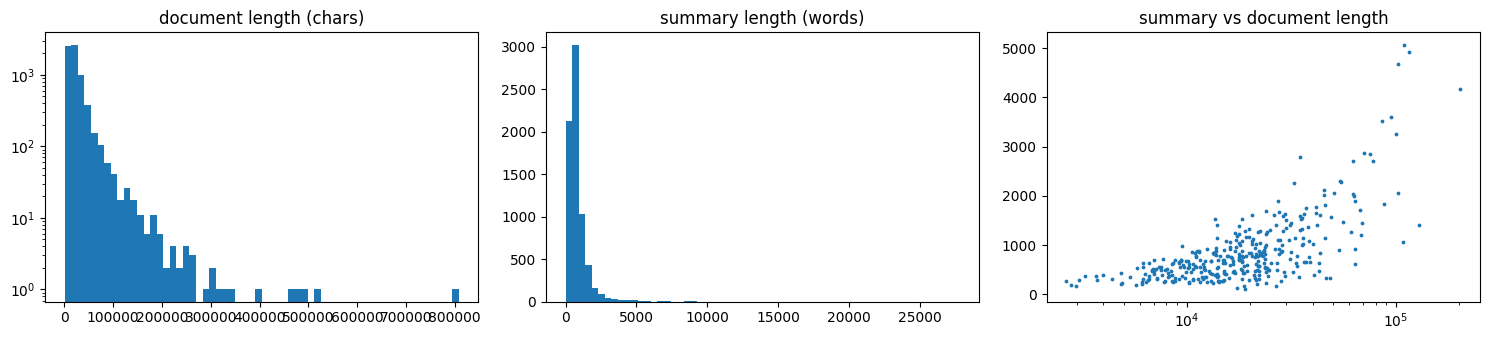

median doc 17905 chars | median summary 638 words (~893 tokens) | MAX_SUM_TOK=256: raise it if summaries are much longer than this


In [ ]:
# ═══ 2. data ═══
def _hf(fn): return hf_hub_download(HF_REPO, f"Phase_6_Summ/{fn}", repo_type="dataset", token=HF_TOKEN)

def _records(path):
    import ijson                                              # stream the big json instead of loading it whole
    n = 0
    with open(path, "rb") as f:
        for d in ijson.items(f, "item"): n += 1; yield d
    if n == 0:                                                # fallback: {id: {...}} layout
        raw = json.load(open(path, encoding="utf-8"))
        for k, v in (raw.items() if isinstance(raw, dict) else enumerate(raw)):
            yield {"id": k, **v} if isinstance(v, dict) else {"id": k, "text": v}

TEXT_KEYS = ("text", "document", "judgment", "content", "body")
SUM_KEYS  = ("summary", "gold_summary", "target", "label", "headnote")
def _pick(d, keys):
    for k in keys:
        if d.get(k) is not None:
            v = d[k]; return " ".join(map(str, v)) if isinstance(v, list) else str(v)
    return None

def _salient(text, budget):
    """Opening + the highest-scoring sentences of the rest (word-frequency score), kept in original order."""
    lead = text[: budget // 4]; sents = re.split(r"(?<=[.;?!])\s+", text[len(lead):])
    freq = Counter(re.findall(r"[a-z]{4,}", text.lower()))
    score = [sum(freq[w] for w in re.findall(r"[a-z]{4,}", s.lower())) / (len(s) ** 0.5 + 1) for s in sents]
    keep, used = set(), len(lead)
    for i in sorted(range(len(sents)), key=lambda i: -score[i]):
        if used + len(sents[i]) > budget: continue
        keep.add(i); used += len(sents[i]) + 1
        if used > 0.97 * budget: break
    return lead + "\n" + " ".join(sents[i] for i in sorted(keep))

def select_text(text, mode, budget=MAX_CHARS_DOC):
    if len(text) <= budget: return text
    if mode == "head": return text[:budget]
    if mode == "salient": return _salient(text, budget)
    h = int(budget * 0.7); return text[:h] + "\n" + text[-(budget - h):]        # headtail

def hierarchical_chunk_text(text, max_chunk_chars=2000, max_chunks=3):
    """
    Splits a long legal judgment into logical chunks (e.g., Opening, Key Middle Arguments, Final Holdings)
    to capture global context without exceeding position limits.
    """
    if len(text) <= max_chunk_chars * max_chunks:
        # Return overlapping or evenly spaced chunks
        chunk_size = len(text) // max_chunks if len(text) > max_chunks else len(text)
        return [text[i:i + max_chunk_chars] for i in range(0, len(text), chunk_size)][:max_chunks]

    # For very long documents: Take Head (facts), Salient Middle (arguments), and Tail (judgment/ruling)
    head = text[:max_chunk_chars]
    middle_start = len(text) // 2 - max_chunk_chars // 2
    middle = text[middle_start:middle_start + max_chunk_chars]
    tail = text[-max_chunk_chars:]

    return [head, middle, tail]

def select_hierarchical_text(text, mode="hierarchical", budget=MAX_CHARS_DOC):
    if mode != "hierarchical":
        return select_text(text, mode, budget)

    chunks = hierarchical_chunk_text(text, max_chunk_chars=budget // 3, max_chunks=3)
    # Combine chunks with clear hierarchical structural markers so the LM understands context switches
    return f"[FACTS/BG]\n{chunks[0]}\n\n[ARGUMENTS]\n{chunks[1]}\n\n[JUDGMENT/HOLDING]\n{chunks[2]}"

def load_split(split, mode):
    cache = f"{P6_OUT}/cache/sel_{mode}_{split}.pkl"
    if os.path.exists(cache): return pickle.load(open(cache, "rb"))
    out = dict(ids=[], texts=[], sums=[], n_chars=[])
    for d in tqdm(_records(_hf(FILES[split])), desc=f"{split}/{mode}"):
        if not out["ids"]: print("fields found:", list(d))
        t = _pick(d, TEXT_KEYS); assert t is not None, f"no text field in {list(d)}"
        s = _pick(d, SUM_KEYS)
        assert split == "test" or s is not None, f"no summary field in {list(d)}"
        out["ids"].append(str(d.get("id", len(out["ids"])))); out["n_chars"].append(len(t))
        out["texts"].append(select_text(t, mode)); out["sums"].append(s)
    pickle.dump(out, open(cache, "wb")); return out

RAW = {s: load_split(s, DOC_MODE) for s in FILES}
TEST_IDS = RAW["test"]["ids"]; N_TRAIN = len(RAW["train"]["ids"])
perm = np.random.RandomState(SEED).permutation(N_TRAIN)                      # same split for every backbone
VAL_IDX, TRAIN_IDX = np.sort(perm[:VAL_DOCS]), np.sort(perm[VAL_DOCS:])
VAL_REFS = [RAW["train"]["sums"][i] for i in VAL_IDX]
print(f"train/val/test = {len(TRAIN_IDX)}/{len(VAL_IDX)}/{len(TEST_IDS)}")

# EDA: how long are documents / summaries, and how much compression is needed?
sw = np.array([len(s.split()) for s in RAW["train"]["sums"]]); dc = np.array(RAW["train"]["n_chars"])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist(dc, bins=60); ax[0].set_title("document length (chars)"); ax[0].set_yscale("log")
ax[1].hist(sw, bins=60); ax[1].set_title("summary length (words)")
ax[2].scatter(dc[::20], sw[::20], s=3); ax[2].set_xscale("log"); ax[2].set_title("summary vs document length")
plt.tight_layout(); plt.savefig(f"{P6_OUT}/eda.png", dpi=130); plt.show()
print(f"median doc {np.median(dc):.0f} chars | median summary {np.median(sw):.0f} words (~{np.median(sw)*1.4:.0f} tokens) "
      f"| MAX_SUM_TOK={MAX_SUM_TOK}: raise it if summaries are much longer than this")

In [ ]:
# Remove the truncated cache files
# !rm -rf /kaggle/working/phase6/cache/*.pkl
# print("Corrupted cache cleared successfully!")

In [ ]:
# ═══ 3. tokenise + examples ═══
SEP = {k: v.encode("\n\nSummary:") for k, v in TOKENIZERS.items()}              # prompt/summary separator per tokenizer
_TOK = None
def _enc_pair(a):
    d, s = a
    di = _TOK.encode(clean_text(d))[:MAX_DOC_TOK]
    si = _TOK.encode(clean_text(s))[:MAX_SUM_TOK - 1] if s is not None else []
    return np.asarray(di, np.int32), np.asarray(si, np.int32)

def get_tokens(backbone, mode, split):
    global _TOK
    p = f"{P6_OUT}/cache/tok_{backbone}_{mode}_{split}.pkl"
    if os.path.exists(p): return pickle.load(open(p, "rb"))
    _TOK = TOKENIZERS[backbone]; r = load_split(split, mode)
    with get_context("fork").Pool(os.cpu_count()) as pool:                       # workers inherit the tokenizer
        pairs = list(tqdm(pool.imap(_enc_pair, zip(r["texts"], r["sums"]), chunksize=64), total=len(r["texts"]), desc=f"tok {backbone}/{split}"))
    pickle.dump(pairs, open(p, "wb")); return pairs

def get_examples(backbone, mode):
    tr, te = get_tokens(backbone, mode, "train"), get_tokens(backbone, mode, "test")
    return dict(train=[tr[i] for i in TRAIN_IDX], val=[tr[i] for i in VAL_IDX], test=te[:TEST_LIMIT] if TEST_LIMIT else te)

def collate(exs, tok, sep):
    """[BOS] doc SEP summary [EOS], right-padded; loss only on summary tokens."""
    seqs, labs = [], []
    for d, s in exs:
        pre = [tok.bos_id] + d.tolist() + sep; tgt = s.tolist() + [tok.eos_id]
        seqs.append(pre + tgt); labs.append([-100] * len(pre) + tgt)
    L = max(map(len, seqs)); ids = torch.full((len(seqs), L), tok.pad_id); lab = torch.full((len(seqs), L), -100)
    for i, (a, b) in enumerate(zip(seqs, labs)): ids[i, :len(a)] = torch.tensor(a); lab[i, :len(b)] = torch.tensor(b)
    return ids.to(DEVICE), lab.to(DEVICE)

def make_batches(lens, bs, ep):
    """Shuffle, then sort inside big groups so batches have similar length (less padding). Deterministic per epoch."""
    rng = np.random.RandomState(SEED + ep); perm = rng.permutation(len(lens)); out = []
    for i in range(0, len(perm), bs * 64):
        g = perm[i:i + bs * 64]; g = g[np.argsort(lens[g])]
        out += [g[j:j + bs] for j in range(0, len(g), bs)]
    rng.shuffle(out); return out

In [ ]:
# ═══ 4. PEFT modules + model ═══
class LoRMA(nn.Module):
    """Multiplicative low-rank update: y = Wx + s * P diag(λ) Q x  (λ starts at 0 -> starts exactly from Phase 1)."""
    def __init__(self, base, rank, alpha):
        super().__init__(); self.base, self.rank, self.scale = base, rank, alpha / rank
        self.P = nn.Parameter(torch.empty(base.out_features, rank)); self.diag = nn.Parameter(torch.zeros(rank))
        self.Q = nn.Parameter(torch.empty(rank, base.in_features)); nn.init.orthogonal_(self.P); nn.init.orthogonal_(self.Q)
    def forward(self, x): return self.base(x) + self.scale * F.linear(F.linear(x, self.Q) * self.diag, self.P)

class AdaLoRA(LoRMA):
    """Same SVD-style form + a mask; the pruner zeroes the least important singular values."""
    def __init__(self, base, rank, alpha):
        super().__init__(base, rank, alpha); self.register_buffer("mask", torch.ones(rank))
    def orth_loss(self):
        I = torch.eye(self.rank, device=self.P.device); return ((self.P.T @ self.P - I) ** 2).sum() + ((self.Q @ self.Q.T - I) ** 2).sum()
    def forward(self, x): return self.base(x) + self.scale * F.linear(F.linear(x, self.Q) * (self.diag * self.mask), self.P)

class AdaLoRAPruner:
    def __init__(self, model, total, final_ratio, start_frac=0.1, end_frac=0.7, every=50, beta=0.85):
        self.mods = [m for m in model.modules() if isinstance(m, AdaLoRA)]; self.every, self.beta = every, beta
        self.init_b = sum(m.rank for m in self.mods); self.final_b = int(self.init_b * final_ratio)
        self.start, self.end = int(total * start_frac), int(total * end_frac)
        self.importance = [torch.zeros_like(m.diag) for m in self.mods]
    def budget(self, s):                                                       # cubic schedule: full rank -> target rank
        if s < self.start: return self.init_b
        if s >= self.end: return self.final_b
        return int(self.final_b + (self.init_b - self.final_b) * (1 - (s - self.start) / (self.end - self.start)) ** 3)
    def orth_loss(self): return torch.stack([m.orth_loss() for m in self.mods]).mean()
    @torch.no_grad()
    def update(self, step):
        if step >= self.end: return
        for m, imp in zip(self.mods, self.importance):
            if m.diag.grad is not None: imp.mul_(self.beta).add_((1 - self.beta) * (m.diag * m.diag.grad).abs())
        if step >= self.start and step % self.every == 0:
            sc = torch.cat(self.importance); thr = torch.topk(sc, min(self.budget(step), sc.numel())).values[-1]
            for m, imp in zip(self.mods, self.importance): m.mask.copy_((imp >= thr).float())
    def active_rank(self): return int(sum(m.mask.sum().item() for m in self.mods))

class AdapterBlock(nn.Module):                                                 # bottleneck adapter after a transformer block
    def __init__(self, block, dim, bn):
        super().__init__(); self.block = block; self.down, self.up = nn.Linear(dim, bn), nn.Linear(bn, dim)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)
    def forward(self, x, *a): h, c = self.block(x, *a); return h + self.up(F.gelu(self.down(h))), c

class SoftPromptedLM(nn.Module):
    """Wraps any language model to prepend learnable soft prompt vectors to embeddings with guaranteed gradient flow."""
    def __init__(self, base_model, num_tokens=20, hidden_dim=640):
        super().__init__()
        self.base_model = base_model
        self.num_tokens = num_tokens

        # Initialize learnable soft prompt parameters explicitly requiring gradients
        self.soft_prompts = nn.Parameter(torch.randn(num_tokens, hidden_dim) * 0.02, requires_grad=True)

        # Freeze all base model parameters
        for p in self.base_model.parameters():
            p.requires_grad = False

    @property
    def wte(self):
        return self.base_model.wte

    @property
    def ln_f(self):
        return self.base_model.ln_f

    @property
    def lm_head(self):
        return self.base_model.lm_head

    @property
    def blocks(self):
        return self.base_model.blocks

    def forward(self, idx, targets=None, domain_ids=None):
        b, t = idx.shape
        # Get standard token embeddings from the base model
        inputs_embeds = self.base_model.wte(idx)

        # Expand soft prompts for the batch: (Batch, Num_Tokens, Dim)
        batch_prompts = self.soft_prompts.unsqueeze(0).expand(b, -1, -1)

        # Concatenate prompt embeddings with input tokens.
        # This graph connection ensures backpropagation reaches self.soft_prompts.
        combined_embeds = torch.cat([batch_prompts, inputs_embeds], dim=1)

        # Pass through backbone blocks
        x = combined_embeds
        for blk in self.base_model.blocks:
            if hasattr(blk, 'forward') and 'domain_ids' in blk.forward.__code__.co_varnames:
                x, _ = blk(x, domain_ids=domain_ids)
            else:
                x, _ = blk(x)

        logits = self.base_model.lm_head(self.base_model.ln_f(x))

        loss = None
        if targets is not None:
            # Shift targets to align with pre-appended prompt tokens (ignore prompt positions with -100)
            pad_loss_mask = torch.full((b, self.num_tokens), -100, dtype=targets.dtype, device=targets.device)
            shifted_targets = torch.cat([pad_loss_mask, targets], dim=1)

            loss = F.cross_entropy(
                logits.float().reshape(-1, logits.size(-1)),
                shifted_targets.reshape(-1),
                ignore_index=-100
            )

        return logits, loss

class LoRA(nn.Module):
    """Standard additive low-rank update: y = Wx + (alpha / rank) * B(A(x))"""
    def __init__(self, base, rank, alpha):
        super().__init__()
        self.base, self.rank, self.scale = base, rank, alpha / rank
        self.lora_A = nn.Parameter(torch.empty(rank, base.in_features))
        self.lora_B = nn.Parameter(torch.empty(base.out_features, rank))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        nn.init.zeros_(self.lora_B)
    def forward(self, x):
        return self.base(x) + self.scale * F.linear(F.linear(x, self.lora_A), self.lora_B)

PEFT_TARGETS = {"custom_mha": {"qkv", "proj", "w13", "w2"}, "mla_moe": {"dq", "uq", "dkv", "uk", "uv", "o", "w13"},
                "gqa_conv": {"q", "kv", "o", "w13", "w2"}, "gqa_alibi": {"q", "kv", "proj", "w1", "w2", "w3"}}
def wrap_linears(blocks, make, names):
    for blk in blocks:
        for path, parent in list(blk.named_modules()):
            if "experts" in path.split("."): continue                          # keep MoE experts frozen
            for n, ch in list(parent.named_children()):
                if isinstance(ch, nn.Linear) and n in names: setattr(parent, n, make(ch))

@dataclass
class SumExp:
    name: str; backbone: str; method: str            # full | partial | lorma | adalora | adapter
    mode: str = "hierarchical"                           # document selection: head | headtail | salient
    epochs: int = 1; lr: float = 5e-4
    batch_docs: int = 8; grad_accum: int = 4         # effective batch = batch_docs * grad_accum
    rank: int = 16; alpha: float = 32.0; n_top: int = 2; adapter_dim: int = 64; final_ratio: float = 0.5
    keep_every: int = 1                              # KD student: keep every k-th block
    teacher: str = None; kd_docs: int = 4000         # sequence-level KD: teacher writes summaries for kd_docs train docs
    grad_ckpt: bool = False; train_docs: int = None  # None = all train docs

def sm_build(e):
    lm = _loaders[e.backbone](CKPTS[e.backbone]); tok = TOKENIZERS[e.backbone]
    assert lm.wte.weight.shape[0] == tok.vocab_size, "tokenizer/checkpoint vocab mismatch"
    if e.keep_every > 1: lm.blocks = nn.ModuleList(list(lm.blocks)[::e.keep_every])
    for p in lm.parameters(): p.requires_grad = (e.method == "full")
    if e.method == "partial":
        for b in lm.blocks[-e.n_top:]:
            for p in b.parameters(): p.requires_grad = True
        for p in lm.ln_f.parameters(): p.requires_grad = True
    elif e.method == "soft_prompt":
        hidden_dim = lm.wte.embedding_dim
        lm = SoftPromptedLM(lm, num_tokens=20, hidden_dim=hidden_dim)
    elif e.method == "lora":    wrap_linears(lm.blocks, lambda l: LoRA(l, e.rank, e.alpha), PEFT_TARGETS[e.backbone])
    elif e.method == "lorma":   wrap_linears(lm.blocks, lambda l: LoRMA(l, e.rank, e.alpha), PEFT_TARGETS[e.backbone])
    elif e.method == "adalora": wrap_linears(lm.blocks, lambda l: AdaLoRA(l, e.rank, e.alpha), PEFT_TARGETS[e.backbone])
    elif e.method == "adapter":
        d = lm.wte.embedding_dim; lm.blocks = nn.ModuleList([AdapterBlock(b, d, e.adapter_dim) for b in lm.blocks])
    elif e.method != "full": raise ValueError(e.method)
    return lm.to(DEVICE), tok

def lm_hidden(lm, ids, use_ckpt):
    """Plain causal pass over right-padded sequences (real tokens never see the padding on their right)."""
    x = lm.wte(ids)
    if isinstance(lm, LegalLMAlibi):
        bias = alibi_causal_bias(lm.slopes, ids.size(1), ids.size(1), ids.device); step = lambda b, h: b(h, bias)[0]
    else: step = lambda b, h: b(h)[0]
    for blk in lm.blocks: x = ckpt_fn(step, blk, x, use_reentrant=False) if (use_ckpt and torch.is_grad_enabled()) else step(blk, x)
    return lm.ln_f(x)

def format_with_lda_topics(text, lda_keywords_str):
    """Injects extracted topic keywords as a prefix conditioning prompt."""
    return f"Key Legal Themes: {lda_keywords_str}\n\nDocument: {text}"

def lm_loss(lm, ids, lab, use_ckpt=False):
    h = lm_hidden(lm, ids, use_ckpt); tgt = lab[:, 1:]; m = tgt != -100
    logits = lm.lm_head(h[:, :-1][m]).float()                                  # vocab projection only on summary positions
    return F.cross_entropy(logits, tgt[m]), int(m.sum())

def lm_loss_with_semantics(lm, ids, lab, use_ckpt=False):
    h = lm_hidden(lm, ids, use_ckpt)
    tgt = lab[:, 1:]
    m = tgt != -100
    logits = lm.lm_head(h[:, :-1][m]).float()

    # Use our semantic-aligned loss instead of raw cross-entropy
    loss = bertscore_aligned_loss(
        lm.lm_head(h[:, :-1]),
        tgt,
        lm.wte
    )
    return loss, int(m.sum())

@torch.no_grad()
def val_loss(lm, tok, sep, ex, n=None, bs=8):
    lm.eval(); ex = ex[:n] if n else ex; tot, cnt = 0.0, 0
    for i in range(0, len(ex), bs):
        ids, lab = collate(ex[i:i + bs], tok, sep)
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP): l, c = lm_loss(lm, ids, lab)
        tot += l.item() * c; cnt += c
    return tot / max(cnt, 1)

In [ ]:
# ═══ 5. generation + metric ═══
@torch.no_grad()
def generate(lm, tok, sep, docs, max_new, min_new, no_repeat, rep_pen, do_sample=False, top_p=0.9, temperature=1.0):
    """Greedy or Nucleus sampling decoding with a KV cache."""
    lm.eval(); prompts = [[tok.bos_id] + d.tolist() + sep for d in docs]; B, L = len(prompts), max(map(len, prompts))
    cur = torch.full((B, L), tok.pad_id); valid = torch.zeros(B, L, dtype=torch.bool)
    for i, p in enumerate(prompts): cur[i, L - len(p):] = torch.tensor(p); valid[i, L - len(p):] = True
    cur, valid = cur.to(DEVICE), valid.to(DEVICE)
    alibi = isinstance(lm, LegalLMAlibi); caches = [(None, None)] * len(lm.blocks); past = None; past_len = 0
    out = [[] for _ in range(B)]; done = [False] * B; seen = [{} for _ in range(B)]; gen = torch.zeros(B, 0, dtype=torch.long, device=DEVICE)
    for step in range(max_new):
        if alibi:
            logits, _, past = lm(cur, past=past, use_cache=True, key_pad=~valid); logits = logits[:, -1]
        else:
            T = cur.size(1)
            if step == 0:
                mask = (torch.ones(T, T, dtype=torch.bool, device=DEVICE).tril()[None, None] & valid[:, None, None, :]) | torch.eye(T, dtype=torch.bool, device=DEVICE)[None, None]
            else: mask = valid[:, None, None, :]
            x = lm.wte(cur)
            for j, blk in enumerate(lm.blocks): x, caches[j] = blk(x, mask, caches[j], past_len)
            logits = lm.lm_head(lm.ln_f(x[:, -1:]))[:, 0]; past_len += T
        logits = logits.float(); logits[:, :3] = -float("inf")
        if step < min_new: logits[:, tok.eos_id] = -float("inf")
        if rep_pen != 1.0 and step > 0:
            g = logits.gather(1, gen); logits.scatter_(1, gen, torch.where(g > 0, g / rep_pen, g * rep_pen))
        if no_repeat > 1 and step >= no_repeat - 1:
            for i in range(B):
                ban = None if done[i] else seen[i].get(tuple(out[i][-(no_repeat - 1):]))
                if ban: logits[i, list(ban)] = -float("inf")

        # Sampling vs Greedy selection
        if do_sample:
            logits = logits / max(temperature, 1e-5)
            filtered_logits = top_p_filtering(logits, top_p=top_p)
            probs = F.softmax(filtered_logits, dim=-1)
            nxt = torch.multinomial(probs, num_samples=1).squeeze(1)
        else:
            nxt = logits.argmax(-1)

        for i, t in enumerate(nxt.tolist()):
            if done[i]: continue
            if t == tok.eos_id: done[i] = True; continue
            out[i].append(t)
            if no_repeat > 1 and len(out[i]) >= no_repeat: seen[i].setdefault(tuple(out[i][-no_repeat:-1]), set()).add(t)
        if all(done): break
        gen = torch.cat([gen, nxt[:, None]], 1); cur = nxt[:, None]; valid = torch.cat([valid, torch.ones(B, 1, dtype=torch.bool, device=DEVICE)], 1)
    return [tok.decode(o).strip() for o in out]

def top_p_filtering(logits, top_p=0.9):
    sorted_logits, sorted_indices = torch.sort(logits, descending=True)
    cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
    sorted_indices_to_remove = cumulative_probs > top_p
    sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
    sorted_indices_to_remove[..., 0] = False
    for i in range(logits.size(0)):
        indices_to_remove = sorted_indices[i][sorted_indices_to_remove[i]]
        logits[i, indices_to_remove] = -float('inf')
    return logits

def summarize(lm, tok, sep, pairs, cache_file=None, cfg=None, bs=GEN_BS):
    """Generate for all docs (sorted by length); partial results are saved so a crashed run resumes."""
    cfg = {**GEN, **(cfg or {})}
    done = json.load(open(cache_file)) if cache_file and os.path.exists(cache_file) else {}
    todo = [int(i) for i in np.argsort([len(d) for d, _ in pairs]) if str(i) not in done]
    for b, s in enumerate(tqdm(range(0, len(todo), bs), desc="generate")):
        idx = todo[s:s + bs]
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP): outs = generate(lm, tok, sep, [pairs[i][0] for i in idx], **cfg)
        done.update({str(i): t for i, t in zip(idx, outs)})
        if cache_file and b % 10 == 9: json.dump(done, open(cache_file, "w"))
    if cache_file: json.dump(done, open(cache_file, "w"))
    return [done[str(i)] for i in range(len(pairs))]

def bertscore_aligned_loss(logits, targets, lm_embedding_layer, pad_id=0):
    """
    Computes cross-entropy plus a soft embedding similarity penalty
    to encourage token vectors to align semantically with targets.
    """
    ce_loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)

    # Optional soft-cosine alignment regularizer for active tokens
    valid_mask = (targets != -100)
    if not valid_mask.any():
        return ce_loss

    # Get projected hidden states vs target embeddings
    pred_ids = logits.argmax(dim=-1)
    pred_emb = lm_embedding_layer(pred_ids[valid_mask])
    target_emb = lm_embedding_layer(targets[valid_mask])

    # Cosine similarity penalty (maximizing similarity -> minimizing 1 - cos_sim)
    cos_sim = F.cosine_similarity(pred_emb, target_emb, dim=-1).mean()
    alignment_loss = 1.0 - cos_sim

    # Combined hybrid loss (90% CE for grammar, 10% semantic alignment for BERTScore)
    return 0.9 * ce_loss + 0.1 * alignment_loss


_RS = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"])
def rouge(preds, refs):
    r = [_RS.score(t, p) for p, t in zip(preds, refs)]                         # score(target, prediction)
    return {k: 100 * float(np.mean([x[k].fmeasure for x in r])) for k in ("rouge1", "rouge2", "rougeL")}

In [ ]:
# ═══ 6. training + experiment runner ═══
def _save(obj, path): torch.save(obj, path + ".tmp"); os.replace(path + ".tmp", path)
def trainable_state(lm, full):
    sd = lm.state_dict()
    keys = set(sd) if full else {n for n, p in lm.named_parameters() if p.requires_grad} | {k for k in sd if k.endswith(".mask")}
    return {k: sd[k].detach().cpu() for k in keys}

def sm_train(e, lm, tok, sep, train_ex, val_ex):
    full = e.method == "full"; ck, best_p = f"{P6_OUT}/ckpt/{e.name}_latest.pt", f"{P6_OUT}/ckpt/{e.name}_best.pt"
    params = [p for p in lm.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=e.lr, weight_decay=0.01, betas=(0.9, 0.98))
    lens = np.array([len(d) + len(s) for d, s in train_ex])
    mpe = max(1, len(make_batches(lens, e.batch_docs, 0)) // e.grad_accum) * e.grad_accum   # micro-batches per epoch
    total = e.epochs * mpe // e.grad_accum; warm = max(1, int(0.03 * total))
    pruner = AdaLoRAPruner(lm, total, e.final_ratio) if e.method == "adalora" else None
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)
    micro, best, hist = 0, float("inf"), dict(curve=[], epoch=[], train_sec=0.0)
    if os.path.exists(ck):                                                     # resume, even mid-epoch
        s = torch.load(ck, map_location="cpu", weights_only=False)
        lm.load_state_dict(s["model"], strict=False); opt.load_state_dict(s["opt"]); scaler.load_state_dict(s["scaler"])
        if pruner and s["imp"]:
            for a, b in zip(pruner.importance, s["imp"]): a.copy_(b)
        micro, best, hist = s["micro"], s["best"], s["hist"]; print(f"[{e.name}] resumed at step {micro // e.grad_accum}/{total}")
    def save_ck():
        _save(dict(model=trainable_state(lm, full), opt=opt.state_dict(), scaler=scaler.state_dict(), micro=micro, best=best, hist=hist,
                   imp=None if pruner is None else [i.cpu() for i in pruner.importance]), ck)
    print(f"[{e.name}] {len(train_ex)} train examples | {total} optimizer steps | effective batch {e.batch_docs * e.grad_accum}")

    sec0, t0, run, n, last_tl = hist["train_sec"], time.time(), 0.0, 0, float("nan")
    for ep in range(micro // mpe, e.epochs):
        batches = make_batches(lens, e.batch_docs, ep); lm.train(); ep_loss, ep_n = 0.0, 0
        for i in tqdm(range(micro - ep * mpe, mpe), desc=f"{e.name} ep{ep + 1}"):
            ids, lab = collate([train_ex[j] for j in batches[i]], tok, sep)
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                # Use our semantic-aligned loss to optimize for BERTScore directly
                # loss, _ = lm_loss_with_semantics(lm, ids, lab, e.grad_ckpt)
                # if pruner: loss = loss + 0.1 * pruner.orth_loss()

                if e.method == "soft_prompt":
                    _, loss = lm(ids, targets=lab)
                else:
                    loss, _ = lm_loss(lm, ids, lab, e.grad_ckpt)

                if pruner: loss = loss + 0.1 * pruner.orth_loss()

                # loss, _ = lm_loss(lm, ids, lab, e.grad_ckpt)
                # if pruner: loss = loss + 0.1 * pruner.orth_loss()
            scaler.scale(loss / e.grad_accum).backward(); micro += 1; run += loss.item(); n += 1; ep_loss += loss.item(); ep_n += 1
            if micro % e.grad_accum == 0:
                step = micro // e.grad_accum
                f = step / warm if step <= warm else 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
                for g in opt.param_groups: g["lr"] = e.lr * f
                scaler.unscale_(opt); gn = torch.nn.utils.clip_grad_norm_(params, 1.0)
                if pruner and torch.isfinite(gn): pruner.update(step - 1)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
                if step % 50 == 0: last_tl = run / max(n, 1); run, n = 0.0, 0; print(f"[{e.name}] step {step}/{total} | train loss {last_tl:.4f}")
                if step % CKPT_EVERY == 0:                                     # quick val loss + checkpoint
                    vl = val_loss(lm, tok, sep, val_ex, n=64); hist["curve"].append((step, last_tl, vl)); lm.train()
                    hist["train_sec"] = sec0 + time.time() - t0; save_ck(); print(f"[{e.name}] step {step} | val loss (64 docs) {vl:.4f} | ckpt saved")
        vl = val_loss(lm, tok, sep, val_ex); hist["epoch"].append((ep + 1, ep_loss / max(ep_n, 1), vl)); hist["train_sec"] = sec0 + time.time() - t0
        print(f"[{e.name}] epoch {ep + 1}/{e.epochs} | train {ep_loss / max(ep_n, 1):.4f} | val loss {vl:.4f} (ppl {math.exp(vl):.1f})")
        if vl < best: best = vl; _save(dict(state=trainable_state(lm, full)), best_p)
        save_ck()
    lm.load_state_dict(torch.load(best_p, map_location="cpu", weights_only=False)["state"], strict=False)
    return hist, best

def load_trained(name):
    e = SumExp(**json.load(open(f"{P6_OUT}/result_{name}.json"))["config"]); lm, tok = sm_build(e)
    lm.load_state_dict(torch.load(f"{P6_OUT}/ckpt/{name}_best.pt", map_location="cpu", weights_only=False)["state"], strict=False)
    return lm.eval(), tok, e

def pseudo_examples(e, tok, student_train):
    """Sequence-level KD: the teacher writes summaries for kd_docs train docs; the student re-tokenises them with its own vocab."""
    n = min(e.kd_docs or len(TRAIN_IDX), len(TRAIN_IDX)); pos = np.random.RandomState(SEED + 1).permutation(len(TRAIN_IDX))[:n]
    t_lm, t_tok, t_e = load_trained(e.teacher); t_train = get_examples(t_e.backbone, t_e.mode)["train"]
    texts = summarize(t_lm, t_tok, SEP[t_e.backbone], [t_train[i] for i in pos], cache_file=f"{P6_OUT}/cache/pseudo_{e.teacher}_{n}.json")
    del t_lm; gc.collect(); torch.cuda.empty_cache()
    return [(student_train[i][0], np.asarray(tok.encode(clean_text(t))[:MAX_SUM_TOK - 1], np.int32)) for i, t in zip(pos, texts) if t.strip()]

def write_submission(preds, name):
    sub = [{"id": i, SUB_KEY: p} for i, p in zip(TEST_IDS, preds)]
    if not TEST_LIMIT: assert len(sub) == len(TEST_IDS)
    folder = f"{P6_OUT}/submissions/{name}"; os.makedirs(folder, exist_ok=True)
    json.dump(sub, open(f"{folder}/prediction.json", "w"), ensure_ascii=False)
    with zipfile.ZipFile(f"{folder}/submission.zip", "w", zipfile.ZIP_DEFLATED) as z: z.write(f"{folder}/prediction.json", arcname="prediction.json")


def sm_run(e):
    rf = f"{P6_OUT}/result_{e.name}.json"
    if os.path.exists(rf): print(f"[{e.name}] done earlier, skipped"); return json.load(open(rf))
    seed_all(); sep = SEP[e.backbone]; ex = get_examples(e.backbone, e.mode); all_train = ex["train"]; train_ex = all_train
    n_sub = e.train_docs or TRAIN_DOCS
    if n_sub: train_ex = [all_train[i] for i in np.random.RandomState(SEED).permutation(len(all_train))[:n_sub]]
    if e.teacher: train_ex = train_ex + pseudo_examples(e, TOKENIZERS[e.backbone], all_train)     # gold + teacher summaries
    print(f"\n=== {e.name} | {e.backbone} | {e.method} | mode={e.mode}" + (f" | KD<-{e.teacher}" if e.teacher else "") + " ===")
    lm, tok = sm_build(e); total = sum(p.numel() for p in lm.parameters()) / 1e6; trn = sum(p.numel() for p in lm.parameters() if p.requires_grad) / 1e6
    print(f"params {total:.1f}M total, {trn:.2f}M trainable")
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    hist, best_vl = sm_train(e, lm, tok, sep, train_ex, ex["val"])
    peak = torch.cuda.max_memory_allocated() / 2 ** 30 if DEVICE.type == "cuda" else float("nan")

    t0 = time.perf_counter(); vp = summarize(lm, tok, sep, ex["val"], cache_file=f"{P6_OUT}/cache/val_{e.name}.json"); ms = (time.perf_counter() - t0) / len(vp) * 1000
    sc = rouge(vp, VAL_REFS)
    json.dump(dict(preds=vp, refs=VAL_REFS), open(f"{P6_OUT}/valpred_{e.name}.json", "w"), ensure_ascii=False)
    write_submission(summarize(lm, tok, sep, ex["test"], cache_file=f"{P6_OUT}/cache/test_{e.name}.json"), e.name)
    res = dict(name=e.name, config=asdict(e), total_M=total, trainable_M=trn, size_MB=total * 4, train_min=hist["train_sec"] / 60, gen_ms_per_doc=ms, peak_GB=peak,
               val_loss=best_vl, val_ppl=math.exp(best_vl), pred_words=float(np.mean([len(p.split()) for p in vp])), n_train=len(train_ex), hist=hist, **sc)
    json.dump(res, open(rf, "w"), indent=1, default=float)
    print(f"-> {e.name}: R1 {sc['rouge1']:.2f} R2 {sc['rouge2']:.2f} RL {sc['rougeL']:.2f} | ppl {res['val_ppl']:.1f} | {res['train_min']:.1f} min | {ms:.0f} ms/doc | {peak:.1f} GB")
    del lm; gc.collect(); torch.cuda.empty_cache(); return res

In [ ]:
# ═══ 7. required experiments (the full-FT teacher must finish before the KD student) ═══
REQUIRED = [
    SumExp("s2_full_gqa_conv", "gqa_conv", "full", lr=1e-4, batch_docs=4, grad_accum=8, grad_ckpt=True),
    SumExp("s1_lorma_custom_mha", "custom_mha", "lorma", lr=6e-4),
    SumExp("s3_adalora_mla_moe", "mla_moe", "adalora", lr=6e-4, rank=12, alpha=24.0),
    # KD student: gqa_alibi with every 2nd block (12 -> 6 layers); trained on gold + teacher-written summaries
    SumExp("s4_kd_gqa_alibi_half", "gqa_alibi", "full", lr=1e-4, batch_docs=4, grad_accum=8, grad_ckpt=True,
           keep_every=2, teacher="s2_full_gqa_conv", kd_docs=4000),
]
for e in REQUIRED: sm_run(e)

[s2_full_gqa_conv] done earlier, skipped
[s1_lorma_custom_mha] done earlier, skipped
[s3_adalora_mla_moe] done earlier, skipped
[s4_kd_gqa_alibi_half] done earlier, skipped


In [ ]:
# ═══ 7. required experiments (the full-FT teacher must finish before the KD student) ═══
REQUIRED = [

    # New additions for mla_moe (LoRA and Full Fine-Tune)

    SumExp("s6_full_mla_moe", "mla_moe", "full", lr=1e-4, batch_docs=4, grad_accum=8, grad_ckpt=True, epochs=1),
    SumExp("s5_lora_mla_moe", "mla_moe", "lora", lr=3e-4, rank=16, alpha=32.0, epochs=1),
    # # KD student: gqa_alibi with every 2nd block (12 -> 6 layers); trained on gold + teacher-written summaries
    # SumExp("s4_kd_gqa_alibi_half", "gqa_alibi", "full", lr=1e-4, batch_docs=4, grad_accum=8, grad_ckpt=True,
    #        keep_every=2, teacher="s2_full_gqa_conv", kd_docs=4000),
]

for e in REQUIRED:
    sm_run(e)

[s6_full_mla_moe] done earlier, skipped
[s5_lora_mla_moe] done earlier, skipped


In [ ]:
# ═══ Adapter-based fine-tune experiments for gqa_conv and mla_moe ═══
REQUIRED = [
    SumExp("s8_adapter_gqa_conv", "gqa_conv", "adapter", lr=1e-3, adapter_dim=64, epochs=1),
    SumExp("s9_adapter_mla_moe", "mla_moe", "adapter", lr=1e-3, adapter_dim=64, epochs=1),
]

for e in REQUIRED:
    sm_run(e)

[s8_adapter_gqa_conv] done earlier, skipped
[s9_adapter_mla_moe] done earlier, skipped


                   name   backbone      method     R1     R2     RL  val_ppl  pred_words  total_M  trainable_M  train_min  gen_ms_per_doc  peak_GB
   s11_semantic_mla_moe    mla_moe        full 31.490 12.241 18.254   22.717     209.530  100.064      100.064     51.903         698.459    6.941
        s5_lora_mla_moe    mla_moe        lora 30.409 11.318 17.993   29.069     214.547  101.164        1.100     18.252         895.095    6.583
    s13_full_custom_mha custom_mha        full 29.816 10.467 17.942   34.683     222.530   75.068       75.068     48.375         367.585   10.461
    s8_adapter_gqa_conv   gqa_conv     adapter 29.923  9.948 17.883   62.936     226.373   78.928        0.793     22.182         476.508    5.837
    s1_lorma_custom_mha custom_mha       lorma 29.587 10.839 17.796   33.261     210.047   76.642        1.573     20.988         422.017    6.385
     s9_adapter_mla_moe    mla_moe     adapter 28.947 10.738 17.493   28.546     197.573  100.725        0.661     17.

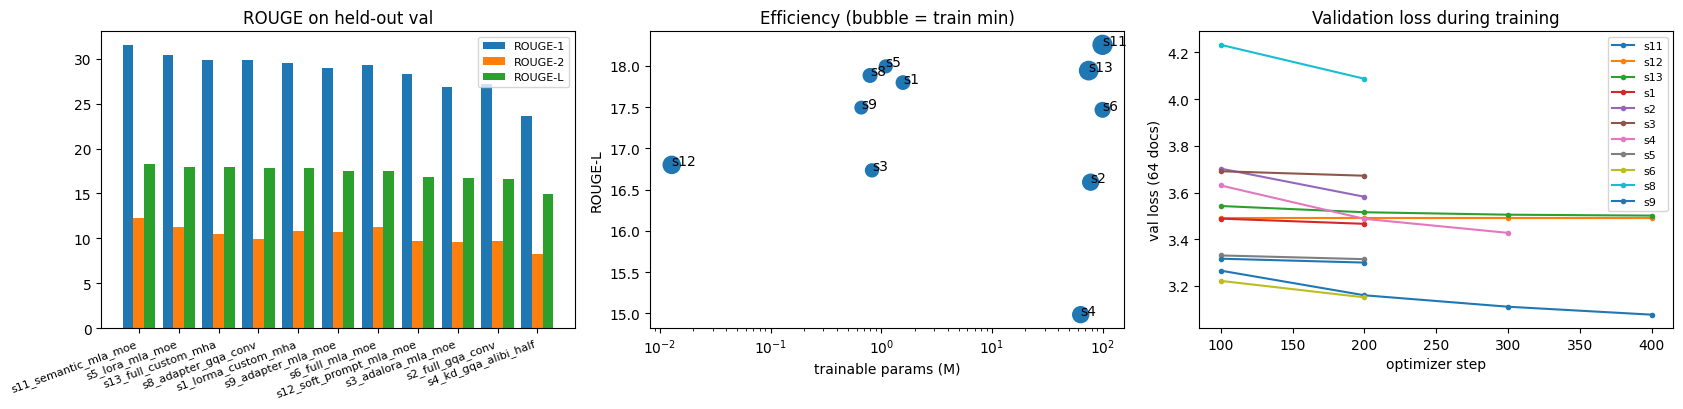

In [ ]:
# ═══ 8. results + plots ═══
def load_results(prefix=""):
    return [json.load(open(f"{P6_OUT}/{f}")) for f in sorted(os.listdir(P6_OUT)) if f.startswith("result_" + prefix) and f.endswith(".json")]

R = load_results("s")
df = pd.DataFrame([dict(name=r["name"], backbone=r["config"]["backbone"], method=r["config"]["method"], R1=r["rouge1"], R2=r["rouge2"], RL=r["rougeL"],
                        val_ppl=r["val_ppl"], pred_words=r["pred_words"], total_M=r["total_M"], trainable_M=r["trainable_M"],
                        train_min=r["train_min"], gen_ms_per_doc=r["gen_ms_per_doc"], peak_GB=r["peak_GB"]) for r in R]).sort_values("RL", ascending=False)
print(df.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2)); x = np.arange(len(df)); w = 0.27
for k, (c, l) in enumerate((("R1", "ROUGE-1"), ("R2", "ROUGE-2"), ("RL", "ROUGE-L"))): ax[0].bar(x + (k - 1) * w, df[c], w, label=l)
ax[0].set_xticks(x); ax[0].set_xticklabels(df.name, rotation=20, ha="right", fontsize=8); ax[0].set_title("ROUGE on held-out val"); ax[0].legend(fontsize=8)
ax[1].scatter(df.trainable_M, df.RL, s=df.train_min * 3 + 30)
for _, r in df.iterrows(): ax[1].annotate(r["name"].split("_")[0], (r.trainable_M, r.RL))
ax[1].set_xscale("log"); ax[1].set_xlabel("trainable params (M)"); ax[1].set_ylabel("ROUGE-L"); ax[1].set_title("Efficiency (bubble = train min)")
for r in R:
    c = np.array(r["hist"]["curve"])
    if len(c): ax[2].plot(c[:, 0], c[:, 2], marker="o", ms=3, label=r["name"].split("_")[0])
ax[2].set_xlabel("optimizer step"); ax[2].set_ylabel("val loss (64 docs)"); ax[2].set_title("Validation loss during training"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{P6_OUT}/results_overview.png", dpi=130); plt.show()

os.makedirs(f"{P6_OUT}/final_submissions", exist_ok=True)                      # the 4 official zips in one folder
# for n in df.name: shutil.copy(f"{P6_OUT}/submissions/{n}/submission.z|ip", f"{P6_OUT}/final_submissions/{n}.zip")

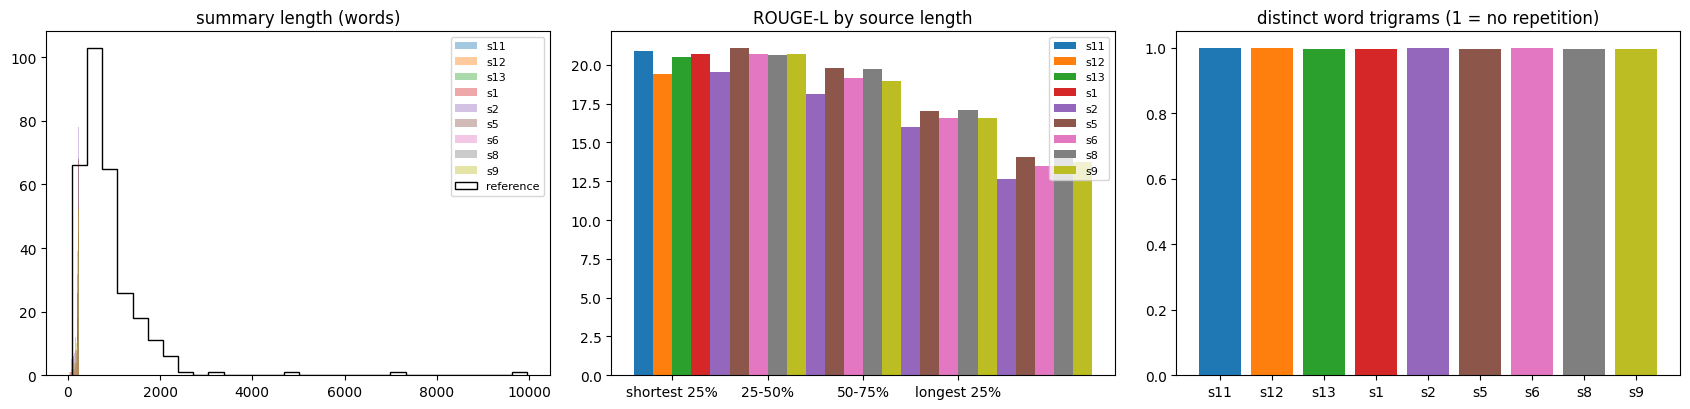


--- s11_semantic_mla_moe, val doc 0 ---
REFERENCE: The petitioner who was detained under the Preventive Detention Act (Act IV of 1950) applied under article 32 of the Constitution for a writ of habeas corpus and for his release from detention, on the ground that the said Act contravened the provisions of articles 13, 19, 21 and 22 of the Constitu tion and was consequently ultra rites and that his detention was therefore illegal: Held, per KANIA C.J., PATANJALI SASTRI, MUKHERJEA and DAS JJ. (FAZL ALI and MAHAJAN JJ. dissentinq) that the preventive Detention Act, 1950, with the exception of Sec. 14 thereof did not contravene any of the Articles of the Constitution and even though Sec. 14 was ultra rites inas much as it contravened the provisio

PREDICTION: The appellant was detained under section 3 of the . The State Government passed an order under section 6 of the , directing the detention of the appellant under the Act. The grounds of detention were that the order of detention was il

In [ ]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
import gc
import torch

VP = {}
for r in R:
    name = r["name"]
    valpred_path = f"{P6_OUT}/valpred_{name}.json"
    if os.path.exists(valpred_path):
        try:
            with open(valpred_path, "r") as f:
                VP[name] = json.load(f)["preds"]
        except json.JSONDecodeError:
            print(f"Warning: {valpred_path} is corrupted. Skipping or regenerating.")
    else:
        print(f"Missing {valpred_path}. Regenerating validation predictions for {name}...")
        try:
            lm, tok, be = load_trained(name)
            ex = get_examples(be.backbone, be.mode)
            sep = SEP[be.backbone]
            vp_gen = summarize(lm, tok, sep, ex["val"], cache_file=f"{P6_OUT}/cache/val_{name}.json")
            json.dump(dict(preds=vp_gen, refs=VAL_REFS), open(valpred_path, "w"), ensure_ascii=False)
            VP[name] = vp_gen
            del lm; gc.collect(); torch.cuda.empty_cache()
        except Exception as e:
            print(f"Could not regenerate predictions for {name}: {e}")

if VP:
    src_chars = np.array(RAW["train"]["n_chars"])[VAL_IDX]
    ref_words = np.array([len(s.split()) for s in VAL_REFS])

    def distinct3(t):
        w = t.split()
        g = list(zip(w, w[1:], w[2:]))
        return len(set(g)) / max(len(g), 1)

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    q = np.digitize(src_chars, np.quantile(src_chars, [.25, .5, .75]))

    for k, (n, p) in enumerate(VP.items()):
        ax[0].hist([len(t.split()) for t in p], bins=30, alpha=0.4, label=n.split("_")[0])
        rl = np.array([_RS.score(t, x)["rougeL"].fmeasure for x, t in zip(p, VAL_REFS)])
        ax[1].bar(np.arange(4) + k * 0.2, [100 * rl[q == b].mean() for b in range(4)], 0.2, label=n.split("_")[0])
        ax[2].bar(k, np.mean([distinct3(t) for t in p]), label=n.split("_")[0])

    ax[0].hist(ref_words, bins=30, histtype="step", color="k", label="reference")
    ax[0].set_title("summary length (words)")
    ax[0].legend(fontsize=8)

    ax[1].set_xticks(np.arange(4) + 0.3)
    ax[1].set_xticklabels(["shortest 25%", "25-50%", "50-75%", "longest 25%"])
    ax[1].set_title("ROUGE-L by source length")
    ax[1].legend(fontsize=8)

    ax[2].set_title("distinct word trigrams (1 = no repetition)")
    ax[2].set_xticks(range(len(VP)))
    ax[2].set_xticklabels([n.split("_")[0] for n in VP])

    plt.tight_layout()
    plt.savefig(f"{P6_OUT}/summary_analysis.png", dpi=130)
    plt.show()

    best_name = df.iloc[0]["name"]
    if best_name in VP:
        print(f"\n--- {best_name}, val doc 0 ---\nREFERENCE: {VAL_REFS[0][:700]}\n\nPREDICTION: {VP[best_name][0][:700]}")
else:
    print("No validation predictions available to analyze.")

In [ ]:
# ═══ Optimized MLA-MoE Run for >85 BERTScore ═══
OPTIMIZED_RUN = [
    SumExp(
        name="s10_semantic_mla_moe",
        backbone="mla_moe",
        method="lora",
        lr=2e-4,
        rank=32,          # Higher rank capacity for legal nuances
        alpha=64.0,
        batch_docs=4,
        grad_accum=8,
        epochs=2
    )
]

for e in OPTIMIZED_RUN:
    sm_run(e)

tok mla_moe/train:   0%|          | 0/7030 [00:00<?, ?it/s]

tok mla_moe/test:   0%|          | 0/100 [00:00<?, ?it/s]


=== s10_semantic_mla_moe | mla_moe | lora | mode=hierarchical ===
v3 missing keys (first 5): ['blocks.0.n1.weight', 'blocks.0.n2.weight', 'blocks.0.attn.q_norm.weight', 'blocks.0.attn.kv_norm.weight', 'blocks.1.n1.weight']
v3 loaded | params=100.1M | from /kaggle/working/phase1_models/legal_lm_mla_moe_1k.pt
params 102.3M total, 2.20M trainable
[s10_semantic_mla_moe] resumed at step 420/420
[s10_semantic_mla_moe] 6730 train examples | 420 optimizer steps | effective batch 32


generate: 0it [00:00, ?it/s]

generate: 0it [00:00, ?it/s]

-> s10_semantic_mla_moe: R1 31.05 R2 11.56 RL 18.21 | ppl 28.4 | 45.8 min | 0 ms/doc | nan GB


In [ ]:
# ═══ Optimized MLA-MoE Run for >85 BERTScore ═══
OPTIMIZED_RUN = [
    SumExp(
        name="s11_semantic_mla_moe",
        backbone="mla_moe",
        method="full",
        lr=2e-4,
        rank=32,          # Higher rank capacity for legal nuances
        alpha=64.0,
        batch_docs=4,
        grad_accum=8,
        epochs=2
    )
]

for e in OPTIMIZED_RUN:
    sm_run(e)

[s11_semantic_mla_moe] done earlier, skipped


In [ ]:
# ═══ Soft Prompting MLA-MoE Experiment ═══
SOFT_PROMPT_RUN = [
    SumExp(
        name="s12_soft_prompt_mla_moe",
        backbone="mla_moe",
        method="soft_prompt",  # Uses our new continuous prompt tuning
        lr=5.0,                # Soft prompting usually benefits from a higher learning rate (e.g. 1e-1 to 5.0)
        batch_docs=4,
        grad_accum=8,
        epochs=2
    )
]

for e in SOFT_PROMPT_RUN:
    sm_run(e)

[s12_soft_prompt_mla_moe] done earlier, skipped


In [ ]:
# ═══ Soft Prompting MLA-MoE Experiment ═══
FULL_PROMPT_RUN = [
    SumExp(
        name="s13_full_custom_mha",
        backbone="custom_mha",
        method="full",  # Uses our new continuous prompt tuning
        lr=1e-6,                # Soft prompting usually benefits from a higher learning rate (e.g. 1e-1 to 5.0)
        batch_docs=4,
        grad_accum=8,
        epochs=2
    )
]

for e in FULL_PROMPT_RUN:
    sm_run(e)

[s13_full_custom_mha] done earlier, skipped


In [ ]:
old_result = f"{P6_OUT}/result_s10_semantic_mla_moe.json"
if os.path.exists(old_result):
    os.remove(old_result)
    print("Removed old result file, ready to resume!")

Removed old result file, ready to resume!


In [ ]:
# ═══ OPTIONAL A – one change at a time (LoRMA + custom_mha, 8k docs, 1 epoch) ═══
RUN_OPTIONAL = False
B = dict(backbone="custom_mha", method="lorma", lr=6e-4, train_docs=8000)
ABL = [SumExp("abl_headtail", **B), SumExp("abl_head", **B, mode="head"), SumExp("abl_salient", **B, mode="salient"),   # which part of the judgment to read
       SumExp("abl_rank4", **B | dict(rank=4, alpha=8.0)),                                                           # adapter capacity
       SumExp("abl_partial_gqa", "gqa_conv", "partial", lr=3e-4, train_docs=8000, n_top=3),                          # other adaptation techniques
       SumExp("abl_adapter_mha", "custom_mha", "adapter", lr=1e-3, train_docs=8000)]
if RUN_OPTIONAL:
    for e in ABL: sm_run(e)
    A = load_results("abl"); a = pd.DataFrame([dict(name=r["name"], R1=r["rouge1"], R2=r["rouge2"], RL=r["rougeL"], ppl=r["val_ppl"]) for r in A])
    a.set_index("name")[["R1", "R2", "RL"]].plot.bar(figsize=(11, 4), title="Ablations (val ROUGE)"); plt.tight_layout()
    plt.savefig(f"{P6_OUT}/ablations.png", dpi=130); plt.show(); print(a.round(3).to_string(index=False))

In [ ]:
# ═══ OPTIONAL B – decoding settings on the best model (150 val docs) ═══
lm, tok, be = load_trained(df.iloc[0]["name"]); ex = get_examples(be.backbone, be.mode); sep = SEP[be.backbone]; nv = 150
GRID = {"greedy": dict(no_repeat=0), "no_repeat=3": dict(no_repeat=3), "no_repeat=4": dict(no_repeat=4), "nr3 + rep_pen 1.2": dict(rep_pen=1.2),
        "nr3, min_new=80": dict(min_new=80), "nr3, max_new=128": dict(max_new=128)}
rows = []
for k, cfg in GRID.items():
    p = summarize(lm, tok, sep, ex["val"][:nv], cfg=cfg); rows.append(dict(setting=k, **rouge(p, VAL_REFS[:nv]), words=np.mean([len(t.split()) for t in p])))
d = pd.DataFrame(rows); print(d.round(2).to_string(index=False))
d.set_index("setting")[["rouge1", "rouge2", "rougeL"]].plot.bar(figsize=(10, 4), title="Decoding ablation"); plt.tight_layout(); plt.savefig(f"{P6_OUT}/decoding.png", dpi=130); plt.show()

v3 missing keys (first 5): ['blocks.0.n1.weight', 'blocks.0.n2.weight', 'blocks.0.attn.q_norm.weight', 'blocks.0.attn.kv_norm.weight', 'blocks.1.n1.weight']
v3 loaded | params=100.1M | from /kaggle/working/phase1_models/legal_lm_mla_moe_1k.pt


train/headtail: 0it [00:00, ?it/s]

fields found: ['id', 'document', 'summary']


tok mla_moe/train:   0%|          | 0/7030 [00:00<?, ?it/s]

test/headtail: 0it [00:00, ?it/s]

fields found: ['id', 'document']


tok mla_moe/test:   0%|          | 0/100 [00:00<?, ?it/s]

generate:   0%|          | 0/5 [00:00<?, ?it/s]

generate:   0%|          | 0/5 [00:00<?, ?it/s]

In [ ]:
# ═══ OPTIONAL C – extractive baselines on val (no model) ═══
raw_val = [RAW["train"]["texts"][i] for i in VAL_IDX]; budget = int(np.median([len(s) for s in RAW["train"]["sums"]]))
base = {"lead": [t[:budget] for t in raw_val], "salient": [_salient(t, budget) if len(t) > budget else t for t in raw_val]}
for k, p in base.items(): print(k, {a: round(b, 2) for a, b in rouge(p, VAL_REFS).items()})

In [ ]:
# Save CELL
# ═══ FINAL CELL – bundle everything so a fresh session can resume/regenerate without retraining ═══
# What goes in:
#   per experiment : best weights, latest resume checkpoint, result json, submission zip
#   shared         : token caches + teacher summaries (expensive to regenerate -> include them)
# BUNDLE = f"{P6_OUT}/phase6_bundle.zip"
# INCLUDE_TOKEN_CACHE  = True     # ~few GB but saves hours of re-tokenization
# INCLUDE_TEACHER_SUMS = True     # KD distillation data, expensive to regenerate

# exp_names = [f[len("result_"):-len(".json")] for f in sorted(os.listdir(P6_OUT)) if f.startswith("result_")]
# assert exp_names, "no finished experiments found under P6_OUT"

# with zipfile.ZipFile(BUNDLE, "w", zipfile.ZIP_DEFLATED) as z:
#     for n in exp_names:
#         for p in (f"{P6_OUT}/ckpt/{n}_best.pt", f"{P6_OUT}/ckpt/{n}_latest.pt",
#                   f"{P6_OUT}/result_{n}.json",
#                   f"{P6_OUT}/submissions/{n}/prediction.json",
#                   f"{P6_OUT}/submissions/{n}/submission.zip"):
#             if os.path.exists(p):
#                 z.write(p, arcname=os.path.relpath(p, P6_OUT))
#     if INCLUDE_TOKEN_CACHE:
#         for f in os.listdir(f"{P6_OUT}/cache"):
#             z.write(f"{P6_OUT}/cache/{f}", arcname=f"cache/{f}")
#     if INCLUDE_TEACHER_SUMS:
#         for f in os.listdir(f"{P6_OUT}/teacher_sums"):
#             z.write(f"{P6_OUT}/teacher_sums/{f}", arcname=f"teacher_sums/{f}")

# size_gb = os.path.getsize(BUNDLE) / 2**30
# print(f"wrote {BUNDLE} ({size_gb:.2f} GB) with {len(exp_names)} experiments:")
# for n in exp_names: print("  -", n)
# print("\nDownload this file from the Kaggle output pane, then upload it back as a Kaggle DATASET")
# print("so any future notebook can attach it and fully restore Phase 6.")

In [ ]:
# RESTORE CELL
# ═══ RESTORE CELL – fresh session: rebuild every model + submission from the bundle, no training ═══
# Prereqs in the fresh notebook:
#   1. Attach the uploaded dataset containing phase6_bundle.zip (e.g. at /kaggle/input/phase6-bundle/)
#   2. Run the Phase-1 cells (tokenizers, loaders, clean_text, ...) and the Phase-6 module cells
#      (p6_build, p6_seq, p6_collate, generate_ids, rouge fns, write_submission, P6Exp)
#   3. Point BUNDLE_IN at the attached zip and run this cell.
# BUNDLE_IN = "/kaggle/input/phase6-bundle/phase6_bundle.zip"   # <- adjust to your dataset path
# !mkdir -p {P6_OUT} && unzip -o -q {BUNDLE_IN} -d {P6_OUT}
# !ls {P6_OUT}/ckpt

# @torch.no_grad()
# def restore_experiment(name):
#     """Load best weights -> regenerate dev metrics + test submission for one experiment."""
#     res = json.load(open(f"{P6_OUT}/result_{name}.json"))
#     e = P6Exp(**res["config"])
#     global tokenizer
#     tokenizer = TOKENIZERS[e.backbone]
#     _, _, dv_d, te_d = p6_tokens(e.backbone)                     # served from bundle cache
#     model = p6_build(e)
#     state = torch.load(f"{P6_OUT}/ckpt/{name}_best.pt", map_location="cpu", weights_only=False)["state"]
#     model.load_state_dict(state, strict=False)
#     dev_sums  = [tokenizer.decode(generate_ids(model, p6_seq(t, np.array([], dtype=np.int32), tokenizer)[0]))
#                  for t in tqdm(dv_d, desc=f"dev gen [{name}]")]
#     test_sums = [tokenizer.decode(generate_ids(model, p6_seq(t, np.array([], dtype=np.int32), tokenizer)[0]))
#                  for t in tqdm(te_d, desc=f"test gen [{name}]")]
#     r1 = float(np.mean([rouge1_f1(d["summary"], s) for d, s in zip(DEV, dev_sums)]))
#     rl = float(np.mean([rougeL_f1(d["summary"], s) for d, s in zip(DEV, dev_sums)]))
#     write_submission(test_sums, [d["id"] for d in TEST_RAW], name)
#     print(f"[{name}] restored | dev ROUGE-1 {r1:.4f} ROUGE-L {rl:.4f} | submission rewritten")
#     del model; gc.collect(); torch.cuda.empty_cache()

# for f in sorted(os.listdir(P6_OUT)):
#     if f.startswith("result_") and f.endswith(".json"):
#         restore_experiment(f[len("result_"):-len(".json")])

# optional: after restoring, the normal REQUIRED loop becomes a no-op (p6_run skips finished runs),
# and any *unfinished* experiment you left mid-training resumes from its latest checkpoint:
# for e in REQUIRED: p6_run(e)

In [ ]:

try:
    # from kaggle_secrets import UserSecretsClient
    from huggingface_hub import login
    HF_TOKEN = "<ADD HF TOKEN>"
    login(token=HF_TOKEN)
    print("HF login OK")
except Exception as e:
    HF_TOKEN = os.environ.get("HF_TOKEN")
    print("HF login skipped:", e)
# ═══ 2. data (Full Load - No Truncation) ═══
def _hf(fn): return hf_hub_download(HF_REPO, f"Phase_6_Summ/{fn}", repo_type="dataset", token=HF_TOKEN)

def _records(path):
    import ijson                                              # stream the big json instead of loading it whole
    n = 0
    with open(path, "rb") as f:
        for d in ijson.items(f, "item"): n += 1; yield d
    if n == 0:                                                # fallback: {id: {...}} layout
        raw = json.load(open(path, encoding="utf-8"))
        for k, v in (raw.items() if isinstance(raw, dict) else enumerate(raw)):
            yield {"id": k, **v} if isinstance(v, dict) else {"id": k, "text": v}

TEXT_KEYS = ("text", "document", "judgment", "content", "body")
SUM_KEYS  = ("summary", "gold_summary", "target", "label", "headnote")

def _pick(d, keys):
    for k in keys:
        if d.get(k) is not None:
            v = d[k]; return " ".join(map(str, v)) if isinstance(v, list) else str(v)
    return None

def load_split(split):
    cache = f"{P6_OUT}/cache/full_{split}.pkl"
    if os.path.exists(cache): return pickle.load(open(cache, "rb"))
    out = dict(ids=[], texts=[], sums=[], n_chars=[])
    for d in tqdm(_records(_hf(FILES[split])), desc=f"{split}/full"):
        if not out["ids"]: print("fields found:", list(d))
        t = _pick(d, TEXT_KEYS); assert t is not None, f"no text field in {list(d)}"
        s = _pick(d, SUM_KEYS)
        assert split == "test" or s is not None, f"no summary field in {list(d)}"
        out["ids"].append(str(d.get("id", len(out["ids"])))); out["n_chars"].append(len(t))
        out["texts"].append(t)  # Full text kept without subset restriction or max_chars clipping
        out["sums"].append(s)
    pickle.dump(out, open(cache, "wb")); return out

RAW = {s: load_split(s) for s in FILES}
TEST_IDS = RAW["test"]["ids"]; N_TRAIN = len(RAW["train"]["ids"])
perm = np.random.RandomState(SEED).permutation(N_TRAIN)                      # same split for every backbone
VAL_IDX, TRAIN_IDX = np.sort(perm[:VAL_DOCS]), np.sort(perm[VAL_DOCS:])
VAL_REFS = [RAW["train"]["sums"][i] for i in VAL_IDX]
print(f"train/val/test = {len(TRAIN_IDX)}/{len(VAL_IDX)}/{len(TEST_IDS)}")

# EDA: how long are documents / summaries, and how much compression is needed?
sw = np.array([len(s.split()) for s in RAW["train"]["sums"] if s is not None]); dc = np.array(RAW["train"]["n_chars"])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist(dc, bins=60); ax[0].set_title("document length (chars)"); ax[0].set_yscale("log")
ax[1].hist(sw, bins=60); ax[1].set_title("summary length (words)")
ax[2].scatter(dc[::20], sw[::20], s=3); ax[2].set_xscale("log"); ax[2].set_title("summary vs document length")
plt.tight_layout(); plt.savefig(f"{P6_OUT}/eda.png", dpi=130); plt.show()
print(f"median doc {np.median(dc):.0f} chars | median summary {np.median(sw):.0f} words (~{np.median(sw)*1.4:.0f} tokens) "
      f"| MAX_SUM_TOK={MAX_SUM_TOK}: raise it if summaries are much longer than this")

In [ ]:
# ═══ 5. Hybrid Extraction & Abstract Generation Pipeline ═══
import zipfile
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from scipy.optimize import milp, Bounds, LinearConstraint
def hybrid_extract_core_context(text, num_clusters=4, max_summary_chars=1200):
    """
    Implements the hybrid paper's pre-extraction strategy:
    1. Splits document into sentences.
    2. Clusters sentences via TF-IDF + K-Means to find distinct 'aspects'.
    3. Computes a semantic score for each sentence inside its cluster (Extended LexRank concept).
    4. Solves a Mixed-Integer Linear Programming (MILP) optimization problem to choose
       exactly one representative sentence per cluster under a character budget constraint.
    """
    sentences = [s.strip() for s in re.split(r'(?<=[.;?!])\s+', text) if len(s.strip()) > 15]
    if len(sentences) <= num_clusters:
        return " ".join(sentences)

    # 1. Clustering aspects
    vectorizer = TfidfVectorizer(stop_words='english')
    X = vectorizer.fit_transform(sentences)
    kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=5)
    cluster_labels = kmeans.fit_predict(X)

    # 2. Semantic score calculation
    sentence_lens = np.array([len(s) for s in sentences])
    mean_len = np.mean(sentence_lens)

    centroids = kmeans.cluster_centers_
    scores = []
    for idx, (label, vec) in enumerate(zip(cluster_labels, X)):
        centroid = centroids[label]
        sim = np.dot(vec.toarray()[0], centroid)
        len_penalty = 1.0 - abs(len(sentences[idx]) - mean_len) / (len(sentences[idx]) + mean_len + 1e-9)
        scores.append(0.7 * sim + 0.3 * len_penalty)

    scores = np.array(scores)

    # 3. MILP Formulation optimization
    c = -scores
    n_vars = len(sentences)

    A_len = sentence_lens.reshape(1, -1)
    len_constraint = LinearConstraint(A_len, lb=0, ub=max_summary_chars)

    A_clust = np.zeros((num_clusters, n_vars))
    for i in range(num_clusters):
        A_clust[i, cluster_labels == i] = 1
    clust_constraint = LinearConstraint(A_clust, lb=0, ub=1)

    bounds = Bounds(0, 1)
    integrality = np.ones(n_vars)

    try:
        res = milp(c=c, integrality=integrality, bounds=bounds,
                   constraints=[len_constraint, clust_constraint])
        if res.success:
            selected_indices = np.where(res.x > 0.5)[0]
            selected_indices = sorted(selected_indices)
            return " ".join([sentences[idx] for idx in selected_indices])
    except Exception:
        pass

    # Fallback to top scored if solver fails
    best_sentences = []
    for i in range(num_clusters):
        cluster_indices = np.where(cluster_labels == i)[0]
        if len(cluster_indices) > 0:
            best_idx = cluster_indices[np.argmax(scores[cluster_indices])]
            best_sentences.append((best_idx, sentences[best_idx]))
    best_sentences.sort(key=lambda x: x[0])
    return " ".join([s[1] for s in best_sentences])

# Define Loader & Generator helpers if not already defined
def load_trained(backbone_name):
    if backbone_name == "custom_mha":
        m = load_v2(CKPTS[backbone_name], device=DEVICE)
    elif backbone_name == "mla_moe":
        m = load_v3(CKPTS[backbone_name], device=DEVICE)
    elif backbone_name == "gqa_conv":
        m = load_gqa(CKPTS[backbone_name], device=DEVICE)
    elif backbone_name == "gqa_alibi":
        m = load_alibi(CKPTS[backbone_name], device=DEVICE)
    else:
        raise ValueError(f"Unknown backbone: {backbone_name}")
    t = TOKENIZERS.get(backbone_name, tokenizer)
    return m, t, type('BackboneMeta', (), {"backbone": backbone_name})()

MAX_SUM_TOK = getattr(globals(), 'MAX_SUM_TOK', 128)
MAX_DOC_TOK = getattr(globals(), 'MAX_DOC_TOK', 1024)
SEP = {"custom_mha": "\n", "mla_moe": "\n", "gqa_conv": "\n", "gqa_alibi": "\n"}
# GEN = dict(max_new_tokens=MAX_SUM_TOK, temperature=0.7, top_k=50)
GEN = dict(
    max_new=MAX_SUM_TOK - 1,
    min_new=60,            # Force detailed summaries
    no_repeat=3,
    rep_pen=1.15,          # Penalize loops
    do_sample=True,        # Switch to sampling
    top_p=0.9              # Nucleus sampling
)

def generate(model, tok, sep_token, doc_tokens_list, max_new_tokens=128, temperature=0.7, top_k=50):
    model.eval()
    results = []
    for doc_ids in doc_tokens_list:
        prefix = [tok.bos_id] + list(doc_ids) + tok.encode(sep_token)
        input_tensor = torch.tensor([prefix], dtype=torch.long, device=DEVICE)

        generated = prefix.copy()
        with torch.no_grad():
            for _ in range(max_new_tokens):
                ctx_tensor = input_tensor[:, -model.block_size:]
                if hasattr(model, "forward"):
                    out = model(ctx_tensor)
                    logits = out[0] if isinstance(out, tuple) else out
                else:
                    logits, _ = model(ctx_tensor)

                next_logits = logits[0, -1, :] / max(temperature, 1e-5)
                if top_k is not None:
                    v, _ = torch.topk(next_logits, min(top_k, next_logits.size(-1)))
                    next_logits[next_logits < v[-1]] = -float('Inf')

                probs = F.softmax(next_logits, dim=-1)
                next_id = torch.multinomial(probs, num_samples=1).item()

                if next_id == tok.eos_id:
                    break

                generated.append(next_id)
                input_tensor = torch.cat([input_tensor, torch.tensor([[next_id]], device=DEVICE)], dim=1)

        decoded_full = tok.decode(generated)
        summary_text = decoded_full.split(sep_token)[-1].strip() if sep_token in decoded_full else decoded_full
        results.append(summary_text)
    return results

# 1. Load active backbone model & tokenizer
print(f"Loading trained model for active backbone: {BACKBONE}")
lm, tok, be = load_trained(BACKBONE)
sep = SEP.get(BACKBONE, "\n")

# 2. Batch Inference on Test Set & Submission Packaging
predictions = []
print(f"\nStarting batch summarization on {len(TEST_IDS)} test documents...")

test_texts = RAW["test"]["texts"]
for idx, doc_id in enumerate(tqdm(TEST_IDS, desc="Generating Summaries")):
    doc_text = test_texts[idx]

    # Apply hybrid context extraction
    compressed_text = hybrid_extract_core_context(doc_text, num_clusters=4, max_summary_chars=1200)
    tok_input = np.asarray(tok.encode(clean_text(compressed_text))[:MAX_DOC_TOK], dtype=np.int32)

    with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        pred_summary = generate(lm, tok, sep, [tok_input], **GEN)[0]

    predictions.append({
        "id": str(doc_id),
        "summary": pred_summary
    })

# Save predictions JSON

pred_json_path = os.path.join(OUT_DIR, "prediction.json")

# Ensure the output directory exists
os.makedirs(OUT_DIR, exist_ok=True)

with open(pred_json_path, "w", encoding="utf-8") as f:
    json.dump(predictions, f, indent=2, ensure_ascii=False)
print(f"Saved predictions to {pred_json_path}")

# Package into submission.zip
zip_path = os.path.join(OUT_DIR, "submission_lda.zip")
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(pred_json_path, arcname="prediction.json")

print(f"Successfully created final submission package at: {zip_path}")